# BT2102 Assignment 3: Beijing property, all visualisations

Level 1: **What is the best investment strategy to maximise returns in Beijing properties?**

| Section | Level-2 question |
|---|---|
| D | What is the current state of the market and where is buyer interest strongest? |
| P1 | What property characteristics should investors target? |
| P2 | Which districts show the strongest and most consistent appreciation? |
| R | Which districts and property types carry the most risk? |

**Files needed in this folder:** `BeijingHousingPrices_featured.csv`, `BeijingHousingPrices.xlsx` (for DOM),
the seven `district_*.csv` statistical-yearbook tables + `manifest.json`, `beijing_districts.geojson`,
`bt2102_style.py` and `fonts/`. Charts are written to `charts/`.

**Data rules used everywhere (check these first when validating):**
1. Years 2012-2017 only (2010-11 and 2018 have too few trades). Ladder ratio > 1 removed as errors.
2. Prices are **median price per m²** (CNY). Growth = CAGR between yearly medians unless stated.
3. **District codes 3 and 11 do not match Appendix A.** Point-in-polygon on the coordinates shows
   code 11 is Tongzhou and code 3 is Yizhuang (Beijing Economic-Technological Development Area). Pinggu is not in the data.
4. **DOM is only recorded properly from mid-2016** (it is 1 for almost every earlier trade), so all DOM
   analysis uses 2017 trades.
5. **Followers grow with the platform** (median 0 in 2012, 31 in 2017), so follower comparisons use 2017 trades only.

In [4]:
# CONFIG: every input path lives here. Repo-relative paths resolve from this notebook's folder.
from pathlib import Path

REPO = Path("../..").resolve()
MAIN_CSV = REPO / "data" / "processed" / "BeijingHousingPrices_featured.csv"   # output of src/featureengineering.py
RAW_XLSX = REPO / "data" / "raw" / "BeijingHousingPrices.xlsx"                 # only for the DOM column
YEARBOOK_DIR = Path(r"C:\Users\kalen\Downloads")                              # seven district_*.csv tables + manifest.json
GEOJSON = Path("beijing_districts.geojson")
for p in [MAIN_CSV, RAW_XLSX, YEARBOOK_DIR / "manifest.json", GEOJSON]:
    assert p.exists(), f"missing input: {p}"

In [2]:
import hashlib
import json
import os
import matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.ticker import FixedLocator, NullLocator, FuncFormatter
from matplotlib.transforms import blended_transform_factory
from shapely.geometry import Point, shape
from shapely.ops import unary_union
from shapely import STRtree

import bt2102_style as bs

bs.setup()
OUT = "charts"
os.makedirs(OUT, exist_ok=True)
SRC = "Lianjia transactions, 2012-2017"
BASE, END = 2012, 2017
YEARS = list(range(BASE, END + 1))
N_YRS = END - BASE
CENTRE = (116.4074, 39.9042)   # Tiananmen; matches distance_to_center_km
pd.set_option("display.width", 160)


def show(fig_path):
    """Display a saved chart inline in the notebook."""
    from IPython.display import Image, display
    display(Image(fig_path))

## 0. Load and prepare data

In [5]:
df = pd.read_csv(MAIN_CSV, low_memory=False)
raw = pd.read_excel(RAW_XLSX, usecols=["id", "DOM"])   # DOM was dropped from the featured file
df["id"] = df["id"].astype(str)
raw["id"] = raw["id"].astype(str)
assert not raw.id.duplicated().any()
df = df.merge(raw, on="id", how="left")

df = df[df.trade_year.between(BASE, END) & (df.ladderRatio <= 1)].copy()
df["date"] = pd.to_datetime(df.tradeTime)
df["ym"] = df.date.dt.to_period("M")
df["quarter"] = df.date.dt.to_period("Q")

BANDS = ["0–5 km", "5–10 km", "10–15 km", "15–20 km", "20–30 km", "30+ km"]
df["band"] = pd.cut(df.distance_to_center_km, [0, 5, 10, 15, 20, 30, 100], labels=BANDS)
df["btype"] = df.buildingType.map({1: "Tower", 3: "Plate + tower", 4: "Plate"})
df["subway_lab"] = df.subway.map({1: "Near subway", 0: "No subway"})
df["elev_lab"] = df.elevator.map({1: "Has elevator", 0: "No elevator"})
df["size_lab"] = df.size_category.map({"<50": "<50 m²", "50-90": "50–90 m²", "90-140": "90–140 m²", "140+": "140+ m²"})
df["age_lab"] = df.age_bucket.map({"0-5": "0–5 yrs", "6-15": "6–15 yrs", "16-30": "16–30 yrs", "30+": "30+ yrs"})
df["floor_lab"] = df.story_type.map({"Low": "Low floor", "Middle": "Middle floor", "High": "High floor", "Top": "Top floor"})
SIZE_ORDER = ["<50 m²", "50–90 m²", "90–140 m²", "140+ m²"]
AGE_ORDER = ["0–5 yrs", "6–15 yrs", "16–30 yrs", "30+ yrs"]
print(f"{len(df):,} trades, {df.DOM.notna().mean():.0%} with DOM")

290,653 trades, 52% with DOM


### District codes: check against real geography
Each trade's coordinates are tested against official district boundaries. The table shows which
boundary most trades of each code fall in. Codes 3 and 11 are the mislabelled ones.

In [ ]:
EN = {"110101": "Dongcheng", "110103": "Dongcheng", "110102": "Xicheng", "110104": "Xicheng",
      "110105": "Chaoyang", "110106": "Fengtai", "110107": "Shijingshan", "110108": "Haidian",
      "110109": "Mentougou", "110111": "Fangshan", "110112": "Tongzhou", "110113": "Shunyi",
      "110114": "Changping", "110115": "Daxing", "110116": "Huairou", "110117": "Pinggu",
      "110228": "Miyun", "110229": "Yanqing"}
gj = json.load(open(GEOJSON, encoding="utf-8"))
polys = {}
for f in gj["features"]:
    nm = EN[f["properties"]["id"]]
    polys[nm] = unary_union([polys[nm], shape(f["geometry"])]) if nm in polys else shape(f["geometry"])
names = list(polys)
tree = STRtree([polys[n] for n in names])
smp = df.sample(50000, random_state=0)
hit = tree.query([Point(x, y) for x, y in zip(smp.Lng, smp.Lat)], predicate="within")
smp["boundary"] = "outside"
smp.iloc[hit[0], smp.columns.get_loc("boundary")] = [names[i] for i in hit[1]]
check = pd.crosstab(smp.district, smp.boundary)
check["share_in_top"] = check.max(axis=1) / check.sum(axis=1)
check["top_boundary"] = check.drop(columns="share_in_top").idxmax(axis=1)
print(check[["top_boundary", "share_in_top"]])

DISTRICT = {1: "Dongcheng", 2: "Fengtai", 3: "Yizhuang", 4: "Daxing", 5: "Fangshan", 6: "Changping",
            7: "Chaoyang", 8: "Haidian", 9: "Shijingshan", 10: "Xicheng", 11: "Tongzhou",
            12: "Mentougou", 13: "Shunyi"}
df["dname"] = df.district.map(DISTRICT)

boundary top_boundary  share_in_top
district                           
1           Dongcheng      0.600763
2             Fengtai      0.771074
3              Daxing      0.893733
4              Daxing      0.921397
5            Fangshan      1.000000
6           Changping      0.988788
7            Chaoyang      0.984627
8             Haidian      0.861565
9         Shijingshan      0.937642
10            Xicheng      0.855193
11           Tongzhou      1.000000
12          Mentougou      0.643478
13             Shunyi      0.942039


### Statistical-yearbook tables (Beijing District Yearbook 2019)
Hashes are checked against `manifest.json`. Chinese district names are mapped to English.
The Economic-Technological Development Area row (北京经济技术开发区) is matched to code 3 (Yizhuang)
only in the housing-supply table; it has no row in the population or income tables.

In [ ]:
manifest = json.load(open(YEARBOOK_DIR / "manifest.json", encoding="utf-8"))
for m in manifest:
    ok = hashlib.sha256(open(YEARBOOK_DIR / m["raw_path"], "rb").read()).hexdigest() == m["sha256"]
    print(f"{m['table_id']:>5}  {m['title_en']:<55} hash ok: {ok}")

CN = {"全市": "Beijing", "东城区": "Dongcheng", "西城区": "Xicheng", "朝阳区": "Chaoyang", "丰台区": "Fengtai",
      "石景山区": "Shijingshan", "海淀区": "Haidian", "门头沟区": "Mentougou", "房山区": "Fangshan",
      "通州区": "Tongzhou", "顺义区": "Shunyi", "昌平区": "Changping", "大兴区": "Daxing", "怀柔区": "Huairou",
      "平谷区": "Pinggu", "密云区": "Miyun", "延庆区": "Yanqing", "北京经济技术开发区": "Yizhuang"}


def yearbook(path):
    t = pd.read_csv(path, skiprows=2, encoding="utf-8-sig")
    t = t[t.iloc[:, 0].isin(CN)].copy()
    t.index = t.iloc[:, 0].map(CN)
    return t.iloc[:, 1:].apply(pd.to_numeric)


pop = yearbook(YEARBOOK_DIR / "district_resident_population_2-1.csv")
income = yearbook(YEARBOOK_DIR / "district_per_capita_disposable_income_2-14.csv")
supply = yearbook(YEARBOOK_DIR / "district_commercial_housing_3-20.csv")
supply

  2-1  Permanent resident population in selected years         hash ok: True
  2-2  Non-local resident population in selected years         hash ok: True
 2-14  Resident per-capita disposable income, 2015-2018        hash ok: True
 2-15  Resident per-capita consumption expenditure, 2015-2018  hash ok: True
  3-7  Permanent population by age                             hash ok: True
 3-49  Resident income and expenditure                         hash ok: True
 3-20  Commodity housing development                           hash ok: True


,房屋施工面积 | 2018,房屋施工面积 | 2017,房屋施工面积 | 增长速度(%),房屋竣工面积 | 2018,房屋竣工面积 | 2017,房屋竣工面积 | 增长速度(%),商品房销售面积 | 2018,商品房销售面积 | 2017,商品房销售面积 | 增长速度(%),#住宅销售面积 | 2018,#住宅销售面积 | 2017,#住宅销售面积 | 增长速度(%)
各区,,,,,,,,,,,,
Beijing,12962.6,12608.6,2.8,1557.9,1466.7,6.2,696.2,875.0,-20.4,526.8,612.8,-14.0
Dongcheng,121.5,154.9,-21.5,17.5,33.8,-48.3,1.0,7.0,-85.6,0.6,4.1,-85.2
Xicheng,73.0,117.7,-38.0,6.0,29.4,-79.7,2.7,3.7,-26.3,1.6,3.1,-46.4
Chaoyang,2235.3,2158.0,3.6,142.8,236.5,-39.6,40.2,102.5,-60.7,32.1,77.5,-58.6
Fengtai,1531.5,1523.0,0.6,103.9,245.1,-57.6,73.2,102.2,-28.4,53.9,76.0,-29.0
Shijingshan,346.5,383.1,-9.5,19.2,61.2,-68.7,28.6,75.0,-61.9,24.1,55.4,-56.5
Haidian,1142.4,1109.2,3.0,145.5,134.8,7.9,26.4,31.8,-16.9,18.5,21.8,-15.0
Mentougou,391.1,419.4,-6.8,102.3,61.3,66.8,32.4,33.1,-2.2,20.4,23.7,-13.8
Fangshan,765.8,779.5,-1.8,158.2,160.2,-1.2,46.5,63.8,-27.1,28.4,40.0,-28.9


## D. Current state of the market and buyer interest

In [ ]:
yearly = df.groupby("trade_year").price.median()
overall_cagr = (yearly[END] / yearly[BASE]) ** (1 / N_YRS) - 1
monthly = df.groupby("ym").agg(price=("price", "median"), trades=("price", "size"), dom=("DOM", "median"))
monthly.index = monthly.index.to_timestamp()
peak_month = monthly.price.idxmax()
POLICY = pd.Timestamp("2017-03-17")   # Beijing "3.17" purchase curbs (higher down payments, shorter loans)
pre = monthly.loc["2016-06":"2017-02"]
post = monthly.loc["2017-04":"2017-12"]
print(f"peak {peak_month:%b %Y} {monthly.price.max():,.0f}; Dec 2017 {monthly.price.iloc[-1]:,.0f} "
      f"({monthly.price.iloc[-1] / monthly.price.max() - 1:+.1%} from peak)")
print(f"trades/month: Jun16-Feb17 {pre.trades.mean():,.0f} -> Apr-Dec17 {post.trades.mean():,.0f} "
      f"({post.trades.mean() / pre.trades.mean() - 1:+.0%})")
print(f"median DOM: Jun16-Feb17 {pre.dom.median():.0f} -> Apr-Dec17 {post.dom.median():.0f} days")

peak Apr 2017 66,949; Dec 2017 57,270 (-14.5% from peak)
trades/month: Jun16-Feb17 6,768 -> Apr-Dec17 2,460 (-64%)
median DOM: Jun16-Feb17 31 -> Apr-Dec17 40 days


**D1. When did the market boom and cool?**

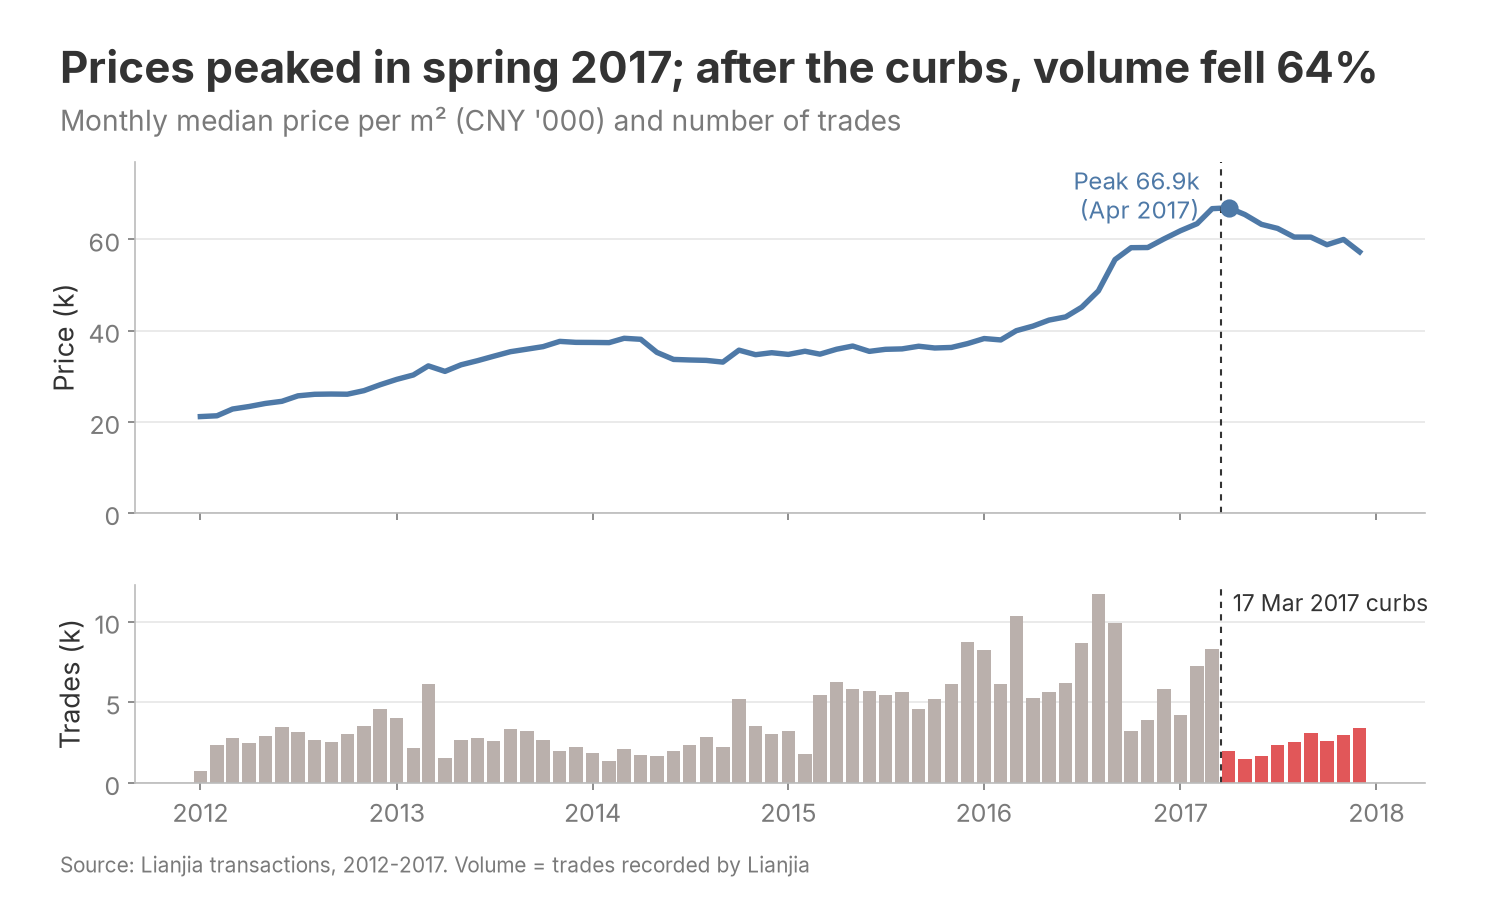

In [ ]:
fig = plt.figure(figsize=bs.FIGSIZE, dpi=bs.DPI)
vol_drop = post.trades.mean() / pre.trades.mean() - 1
fig.text(0.04, 0.955, f"Prices peaked in spring 2017; after the curbs, volume fell {abs(vol_drop):.0%}",
         fontsize=21, fontweight="bold", va="top")
fig.text(0.04, 0.885, "Monthly median price per m² (CNY '000) and number of trades", fontsize=13.5, color=bs.MUTED, va="top")
ax1 = fig.add_axes([0.09, 0.43, 0.86, 0.39])
ax2 = fig.add_axes([0.09, 0.13, 0.86, 0.22], sharex=ax1)
ax1.plot(monthly.index, monthly.price / 1000, color=bs.HIGHLIGHT, lw=2.6)
ax1.scatter([peak_month], [monthly.price.max() / 1000], color=bs.HIGHLIGHT, s=60, zorder=3)
ax1.annotate(f"Peak {monthly.price.max()/1000:.1f}k\n({peak_month:%b %Y})", (peak_month, monthly.price.max() / 1000),
             xytext=(-14, 6), textcoords="offset points", ha="right", va="center", fontsize=11.5, color=bs.HIGHLIGHT)
ax1.set_ylabel("Price (k)")
ax1.set_ylim(0, monthly.price.max() / 1000 * 1.15)
bs.ygrid(ax1)
plt.setp(ax1.get_xticklabels(), visible=False)
ax2.bar(monthly.index, monthly.trades / 1000, width=25,
        color=[bs.NEGATIVE if d >= POLICY else bs.CONTEXT for d in monthly.index])
ax2.set_ylabel("Trades (k)")
bs.ygrid(ax2)
for a in (ax1, ax2):
    a.axvline(POLICY, color=bs.INK, lw=1, ls=(0, (3, 3)))
ax2.text(POLICY, ax2.get_ylim()[1] * 0.98, "  17 Mar 2017 curbs", fontsize=11, va="top", color=bs.INK)
bs.finish(fig, f"{OUT}/D1_boom_and_cooling.png", SRC + ". Volume = trades recorded by Lianjia")
show(f"{OUT}/D1_boom_and_cooling.png")

**D2. How much of the growth came in 2016-2017?**

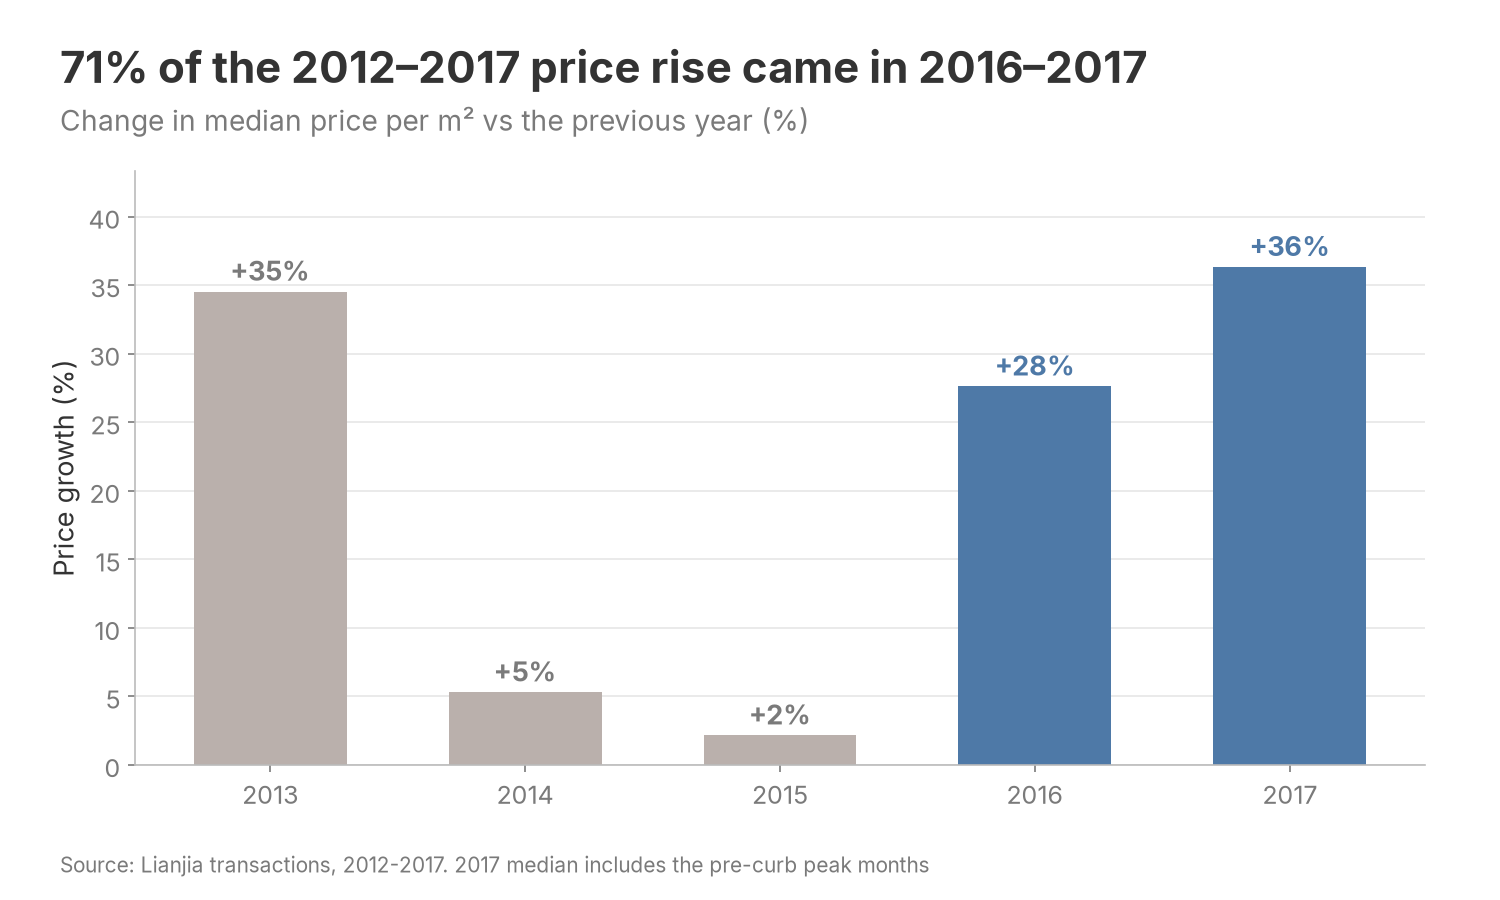

In [ ]:
yoy = yearly.loc[YEARS].pct_change().dropna() * 100
share_1617 = (yearly[2017] - yearly[2015]) / (yearly[2017] - yearly[2012])
fig, ax = bs.new_chart(f"{share_1617:.0%} of the 2012–2017 price rise came in 2016–2017",
                       "Change in median price per m² vs the previous year (%)")
cols = [bs.HIGHLIGHT if y in (2016, 2017) else bs.CONTEXT for y in yoy.index]
ax.bar(yoy.index.astype(str), yoy.values, color=cols, width=0.6)
for i, v in enumerate(yoy.values):
    ax.text(i, v + 0.8, f"{v:+.0f}%", ha="center", fontsize=13, fontweight="bold",
            color=bs.HIGHLIGHT if cols[i] == bs.HIGHLIGHT else bs.MUTED)
ax.set_ylim(0, yoy.max() + 7)
ax.set_ylabel("Price growth (%)")
bs.ygrid(ax)
bs.finish(fig, f"{OUT}/D2_growth_by_year.png", SRC + ". 2017 median includes the pre-curb peak months")
show(f"{OUT}/D2_growth_by_year.png")

**D3. Is the cooling deepening? (DOM and volume, mid-2016 to 2017)**

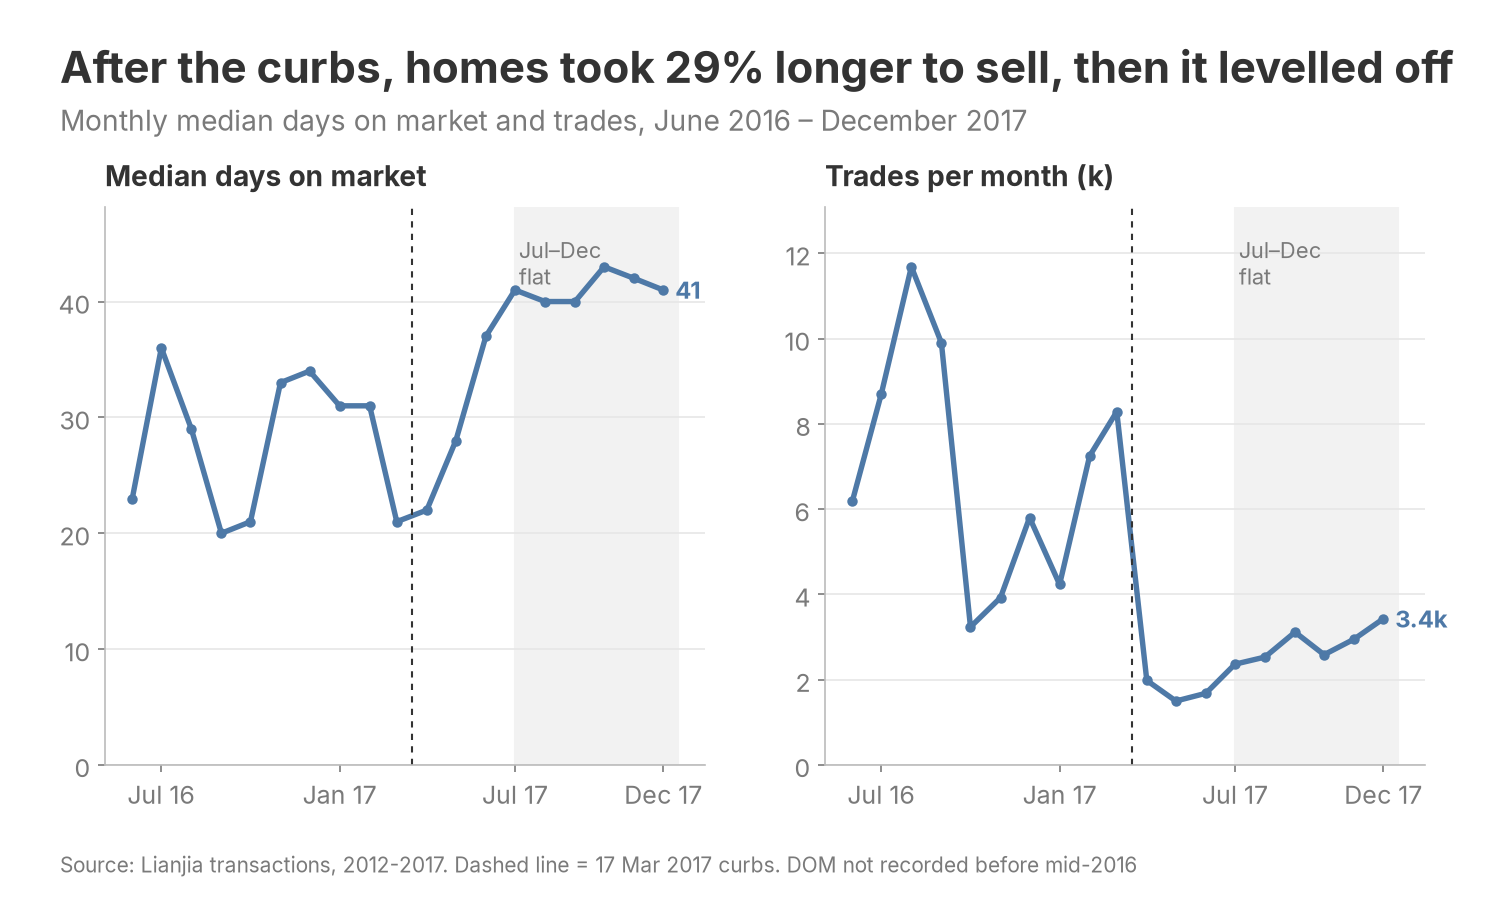

In [ ]:
w = monthly.loc["2016-06":"2017-12"]
fig = plt.figure(figsize=bs.FIGSIZE, dpi=bs.DPI)
dom_up = post.dom.median() / pre.dom.median() - 1
fig.text(0.04, 0.955, f"After the curbs, homes took {dom_up:.0%} longer to sell, then it levelled off",
         fontsize=21, fontweight="bold", va="top")
fig.text(0.04, 0.885, "Monthly median days on market and trades, June 2016 – December 2017", fontsize=13.5, color=bs.MUTED, va="top")
specs = [(w.dom, "Median days on market", lambda v: f"{v:.0f}"), (w.trades / 1000, "Trades per month (k)", lambda v: f"{v:.1f}k")]
for k, (s, lab, fmt) in enumerate(specs):
    ax = fig.add_axes([0.07 + k * 0.48, 0.15, 0.40, 0.62])
    ax.plot(s.index, s.values, color=bs.HIGHLIGHT, lw=2.6, marker="o", ms=4)
    ax.axvline(POLICY, color=bs.INK, lw=1, ls=(0, (3, 3)))
    ax.axvspan(pd.Timestamp("2017-07-01"), s.index.max() + pd.Timedelta(days=15), color="#F2F2F2", zorder=0)
    ax.text(pd.Timestamp("2017-07-05"), s.max() * 1.06, "Jul–Dec\nflat", fontsize=10.5, color=bs.MUTED, va="top")
    ax.set_title(lab, loc="left", fontsize=13.5, fontweight="bold", pad=10)
    ax.set_ylim(0, s.max() * 1.12)
    ax.text(s.index[-1], s.iloc[-1], "  " + fmt(s.iloc[-1]), va="center", fontsize=11.5, color=bs.HIGHLIGHT, fontweight="bold")
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %y"))
    ax.set_xticks(pd.to_datetime(["2016-07-01", "2017-01-01", "2017-07-01", "2017-12-01"]))
    bs.ygrid(ax)
bs.finish(fig, f"{OUT}/D3_cooling_dom_volume.png", SRC + ". Dashed line = 17 Mar 2017 curbs. DOM not recorded before mid-2016")
show(f"{OUT}/D3_cooling_dom_volume.png")

**D4. Which size and age segments attract the most followers per listing? (2017)**

size_lab   <50 m²  50–90 m²  90–140 m²  140+ m²
age_lab                                        
0–5 yrs       212      1496        852      181
6–15 yrs     1968      8059       6652     1630
16–30 yrs    2464     10682       2655      678
30+ yrs      1059      3272         46        2


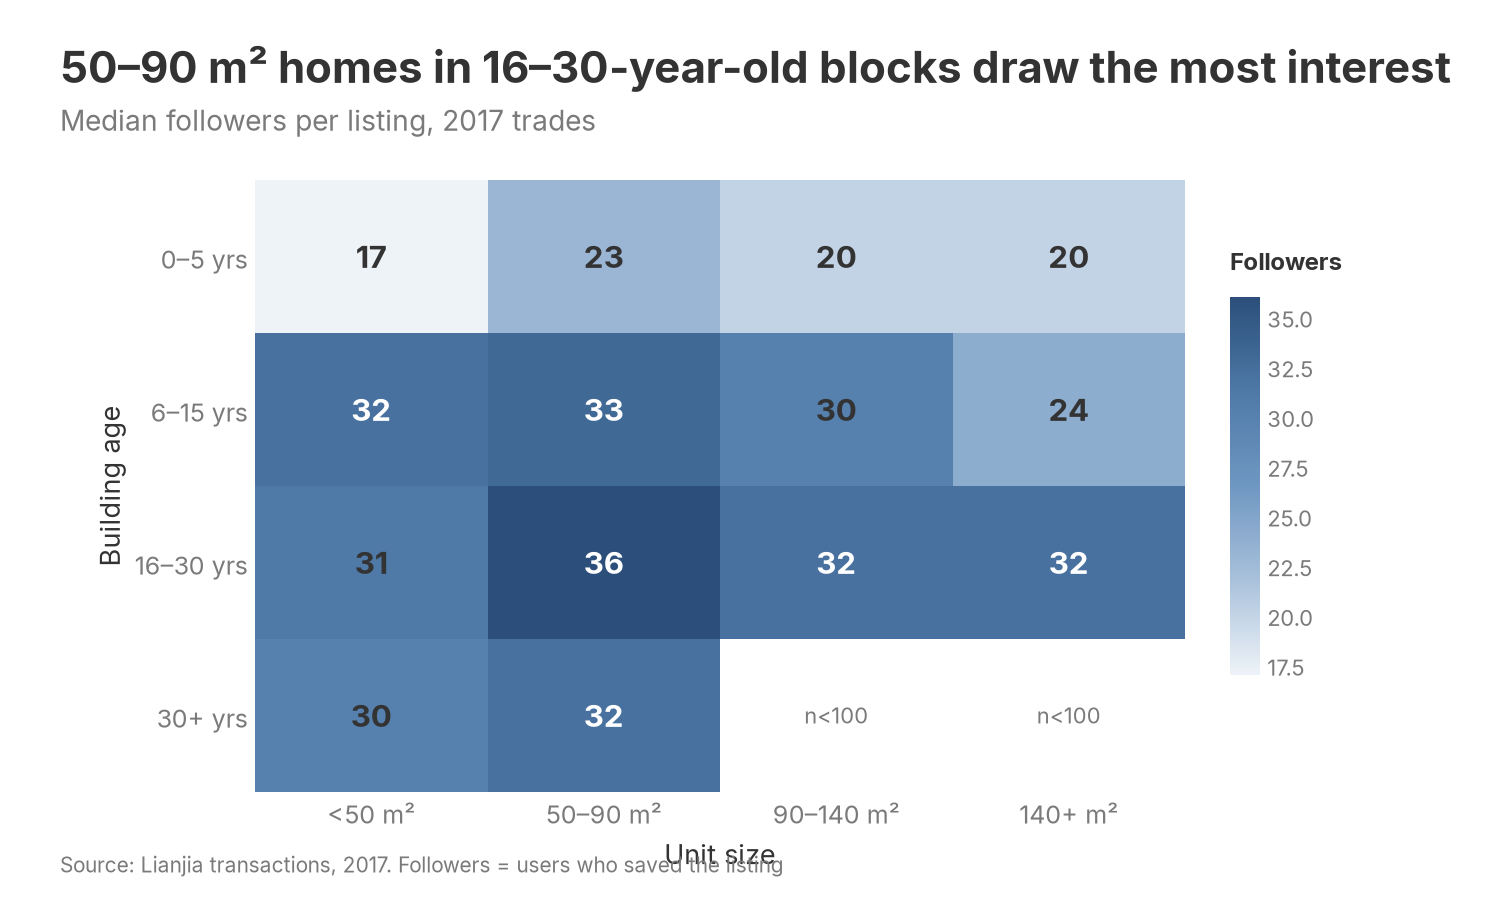

In [ ]:
d17 = df[df.trade_year == 2017]
fol = d17.pivot_table(index="age_lab", columns="size_lab", values="followers", aggfunc="median").loc[AGE_ORDER, SIZE_ORDER]
cnt = d17.pivot_table(index="age_lab", columns="size_lab", values="followers", aggfunc="size").loc[AGE_ORDER, SIZE_ORDER]
fol = fol.where(cnt >= 100)
print(cnt)
best = fol.stack().idxmax()
fig, ax = bs.new_chart(f"{best[1]} homes in {best[0].replace(' yrs', '')}-year-old blocks draw the most interest",
                       "Median followers per listing, 2017 trades", rect=(0.17, 0.12, 0.62, 0.68))
cmap = LinearSegmentedColormap.from_list("b", ["#EEF3F8"] + bs.SEQ_BLUES[1:])
im = ax.imshow(fol.values, cmap=cmap, aspect="auto")
for i in range(fol.shape[0]):
    for j in range(fol.shape[1]):
        v = fol.values[i, j]
        if np.isnan(v):
            ax.text(j, i, "n<100", ha="center", va="center", fontsize=10.5, color=bs.MUTED)
        else:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=15, fontweight="bold",
                    color="white" if v > np.nanpercentile(fol.values, 60) else bs.INK)
ax.set_xticks(range(len(SIZE_ORDER)), SIZE_ORDER)
ax.set_yticks(range(len(AGE_ORDER)), AGE_ORDER)
ax.set_xlabel("Unit size")
ax.set_ylabel("Building age")
ax.tick_params(length=0)
for s_ in ax.spines.values():
    s_.set_visible(False)
cax = fig.add_axes([0.82, 0.25, 0.02, 0.42])
cb = fig.colorbar(im, cax=cax)
cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=10.5, length=0)
fig.text(0.82, 0.70, "Followers", fontsize=11.5, fontweight="bold")
bs.finish(fig, f"{OUT}/D4_followers_size_age.png", "Lianjia transactions, 2017. Followers = users who saved the listing")
show(f"{OUT}/D4_followers_size_age.png")

**D5. How does follower interest differ by characteristic? (2017)**

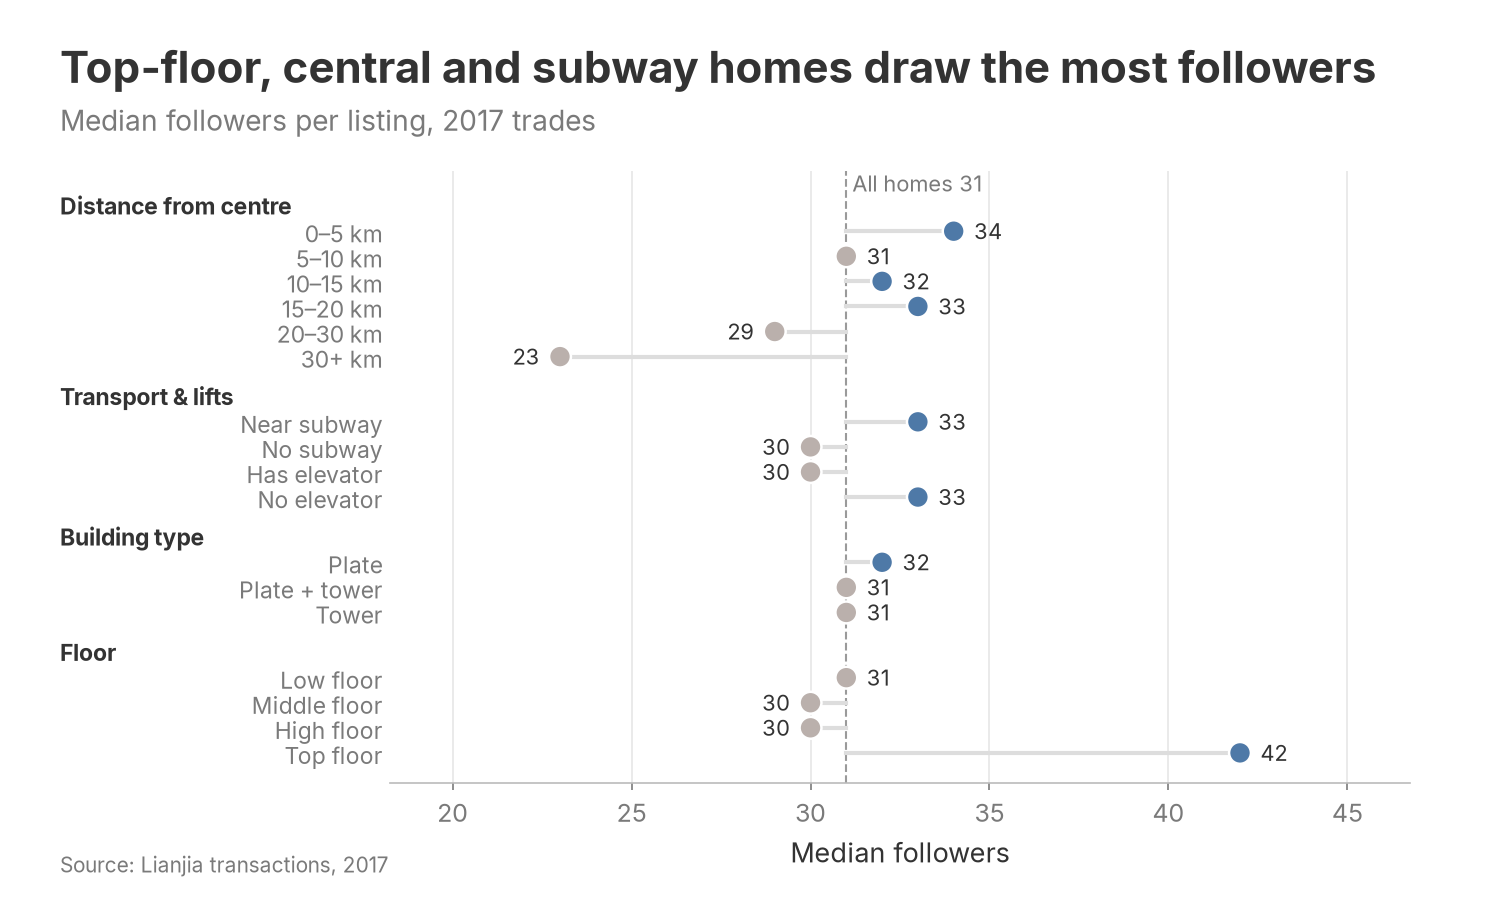

In [ ]:
def grouped_dots(groups, values, title, subtitle, xlabel, path, ref=None, ref_label=None, fmt="{:.0f}",
                 src=SRC, colour_rule=None):
    """Horizontal dot plot with grouped categories. groups = [(header, [labels])], values = dict label->value."""
    rows, heads, y = [], [], 0
    for head, labs in groups:
        heads.append((y, head))
        y += 1
        for lab in labs:
            rows.append((y, lab, values[lab]))
            y += 1
        y += 0.6
    fig, ax = bs.new_chart(title, subtitle, rect=(0.26, 0.13, 0.68, 0.68))
    ys, labs, vals = zip(*rows)
    vals = np.array(vals)
    cols = [colour_rule(v) if colour_rule else bs.HIGHLIGHT for v in vals]
    if ref is not None:
        ax.axvline(ref, color="#9A9A9A", lw=1, ls="--", zorder=1)
        ax.text(ref, -0.9, f" {ref_label}", fontsize=10.5, color=bs.MUTED, va="center")
        for yy, v in zip(ys, vals):
            ax.plot([ref, v], [yy, yy], color="#DDDDDD", lw=2, zorder=1)
    ax.scatter(vals, ys, s=110, color=cols, zorder=3, edgecolor="white", lw=1.2)
    span = vals.max() - vals.min()
    for yy, v, c in zip(ys, vals, cols):
        right = ref is None or v >= ref
        ax.text(v + (span * 0.03 if right else -span * 0.03), yy, fmt.format(v), va="center",
                ha="left" if right else "right", fontsize=10.5, color=bs.INK)
    ax.set_yticks(ys, labs)
    tr = blended_transform_factory(fig.transFigure, ax.transData)
    for yh, head in heads:
        ax.text(0.04, yh, head, transform=tr, ha="left", va="center", fontsize=11, fontweight="bold")
    ax.tick_params(axis="y", length=0, labelsize=11)
    ax.spines["left"].set_visible(False)
    ax.set_ylim(y - 0.4, -1.4)
    ax.set_xlim(vals.min() - span * 0.25, vals.max() + span * 0.25)
    ax.set_xlabel(xlabel)
    bs.xgrid(ax)
    bs.finish(fig, path, src)
    return fig


GROUPS_CHAR = [("Distance from centre", BANDS),
               ("Transport & lifts", ["Near subway", "No subway", "Has elevator", "No elevator"]),
               ("Building type", ["Plate", "Plate + tower", "Tower"]),
               ("Floor", ["Low floor", "Middle floor", "High floor", "Top floor"])]
vals = {}
for col in ["band", "subway_lab", "elev_lab", "btype", "floor_lab"]:
    vals.update(d17.groupby(col, observed=True).followers.median().to_dict())
med17 = d17.followers.median()
grouped_dots(GROUPS_CHAR, vals, "Top-floor, central and subway homes draw the most followers",
             "Median followers per listing, 2017 trades", "Median followers", f"{OUT}/D5_followers_by_characteristic.png",
             ref=med17, ref_label=f"All homes {med17:.0f}",
             colour_rule=lambda v: bs.HIGHLIGHT if v > med17 else bs.CONTEXT,
             src="Lianjia transactions, 2017")
show(f"{OUT}/D5_followers_by_characteristic.png")

**D6. Has new-home demand kept cooling into 2018? (yearbook table 3-20)**

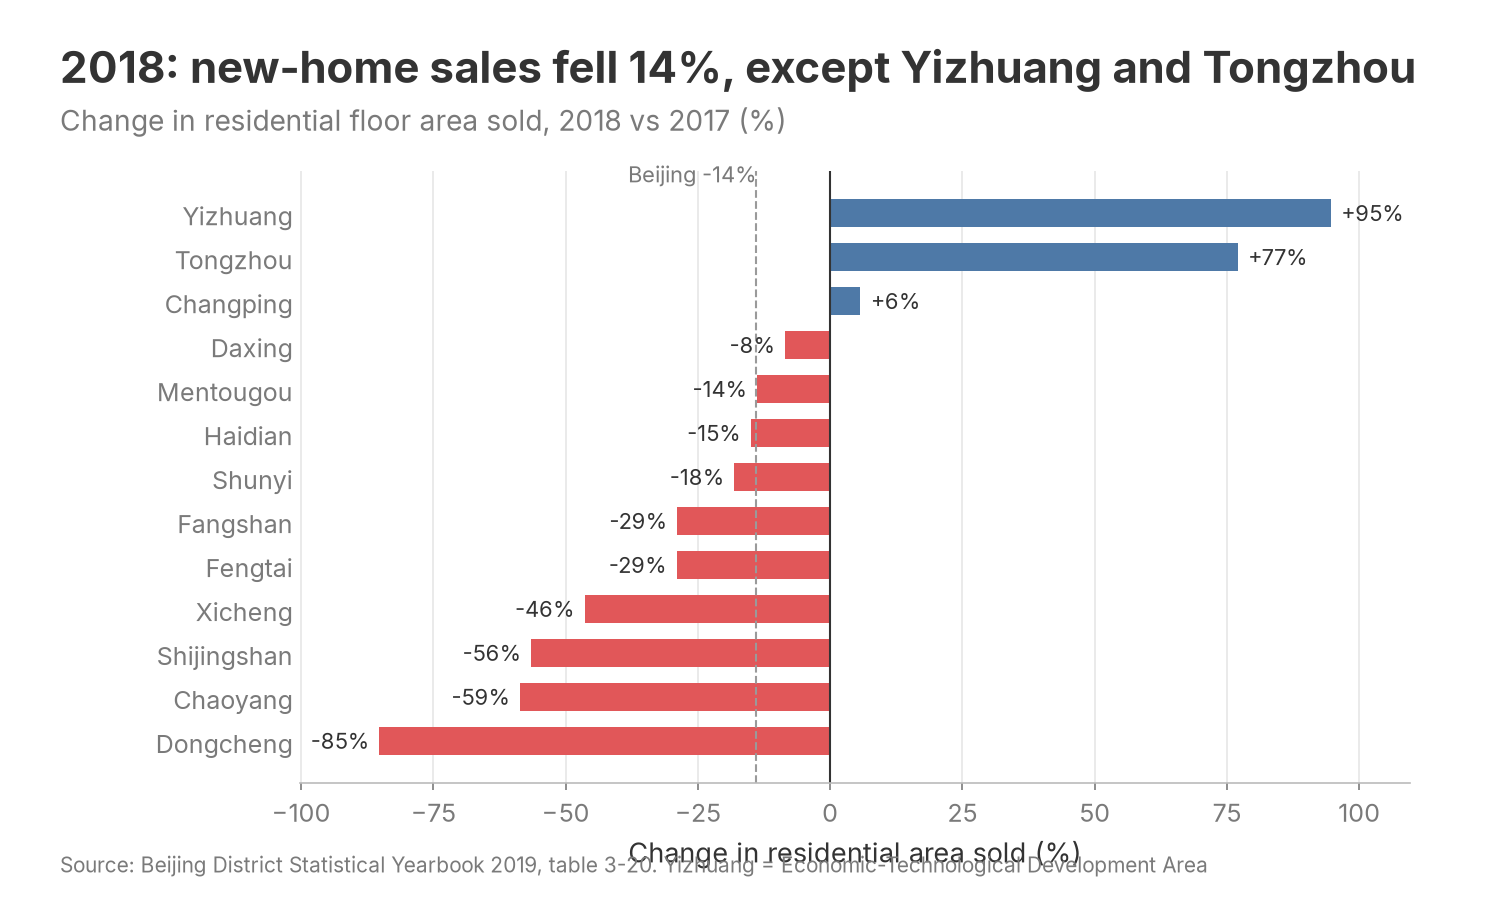

In [ ]:
res = supply["#住宅销售面积 | 增长速度(%)"].drop(["Huairou", "Pinggu", "Miyun", "Yanqing"])
city = res.pop("Beijing")
res = res.sort_values()
fig, ax = bs.new_chart(f"2018: new-home sales fell {abs(city):.0f}%, except Yizhuang and Tongzhou",
                       "Change in residential floor area sold, 2018 vs 2017 (%)", rect=(0.2, 0.13, 0.74, 0.68))
cols = [bs.HIGHLIGHT if v > 0 else bs.NEGATIVE for v in res.values]
ax.barh(res.index, res.values, color=cols, height=0.65)
for i, v in enumerate(res.values):
    ax.text(v + (2 if v >= 0 else -2), i, f"{v:+.0f}%", va="center", ha="left" if v >= 0 else "right", fontsize=10.5)
ax.axvline(0, color=bs.INK, lw=1)
ax.axvline(city, color="#9A9A9A", lw=1, ls="--")
ax.text(city, len(res) - 0.3, f"Beijing {city:+.0f}%", ha="right", fontsize=10.5, color=bs.MUTED)
ax.set_xlim(res.min() - 15, res.max() + 15)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Change in residential area sold (%)")
bs.xgrid(ax)
bs.finish(fig, f"{OUT}/D6_new_home_sales_2018.png",
          "Beijing District Statistical Yearbook 2019, table 3-20. Yizhuang = Economic-Technological Development Area")
show(f"{OUT}/D6_new_home_sales_2018.png")

## P1. Property characteristics to target
(Same charts as before; 1a-1c now keep each group's own colour.)

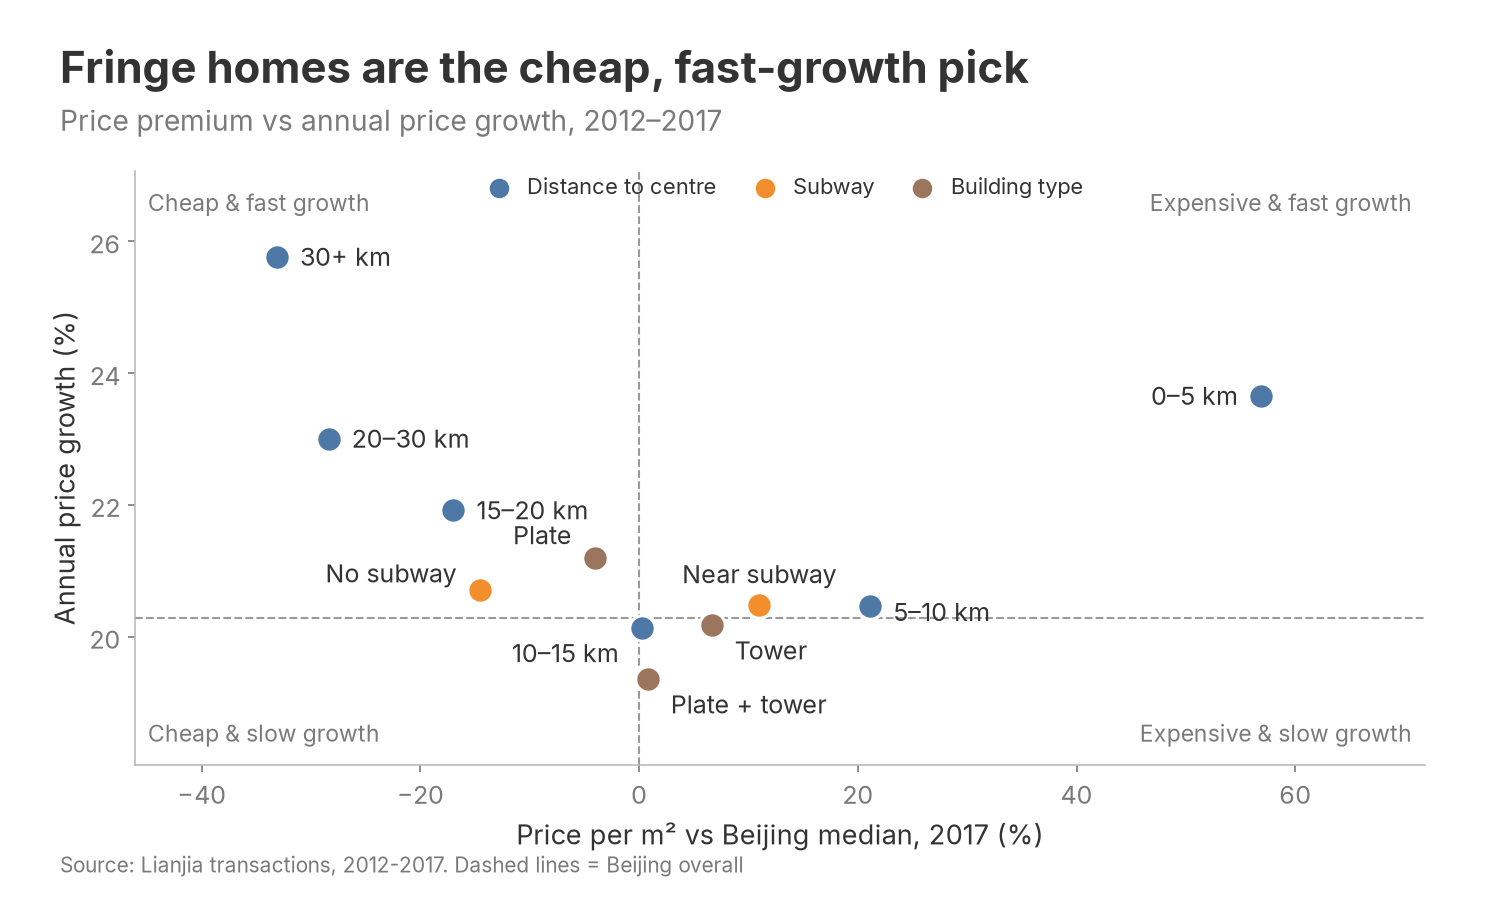

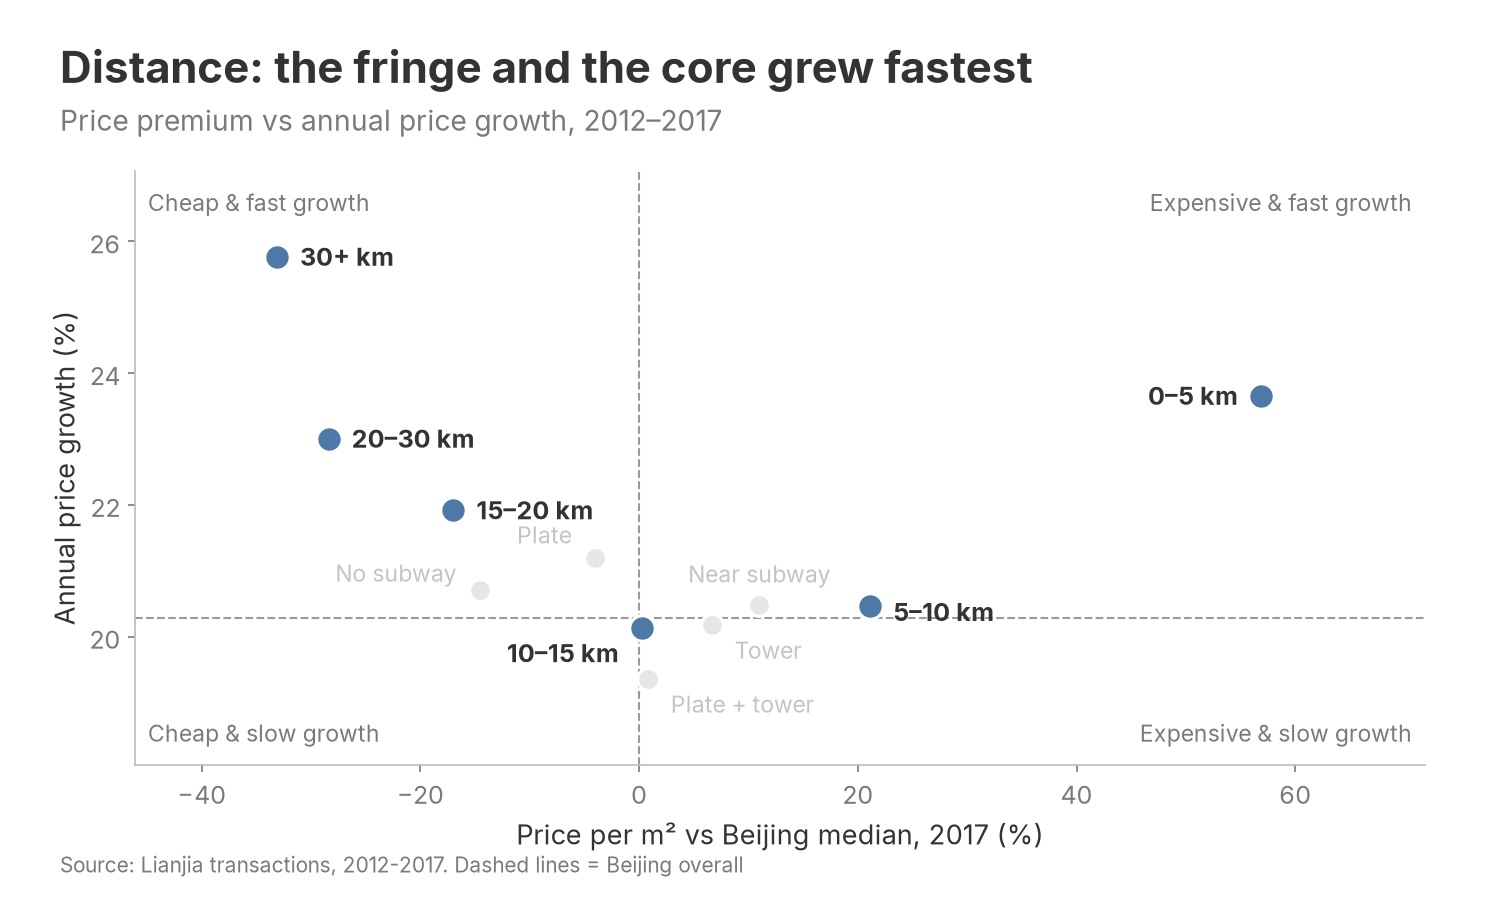

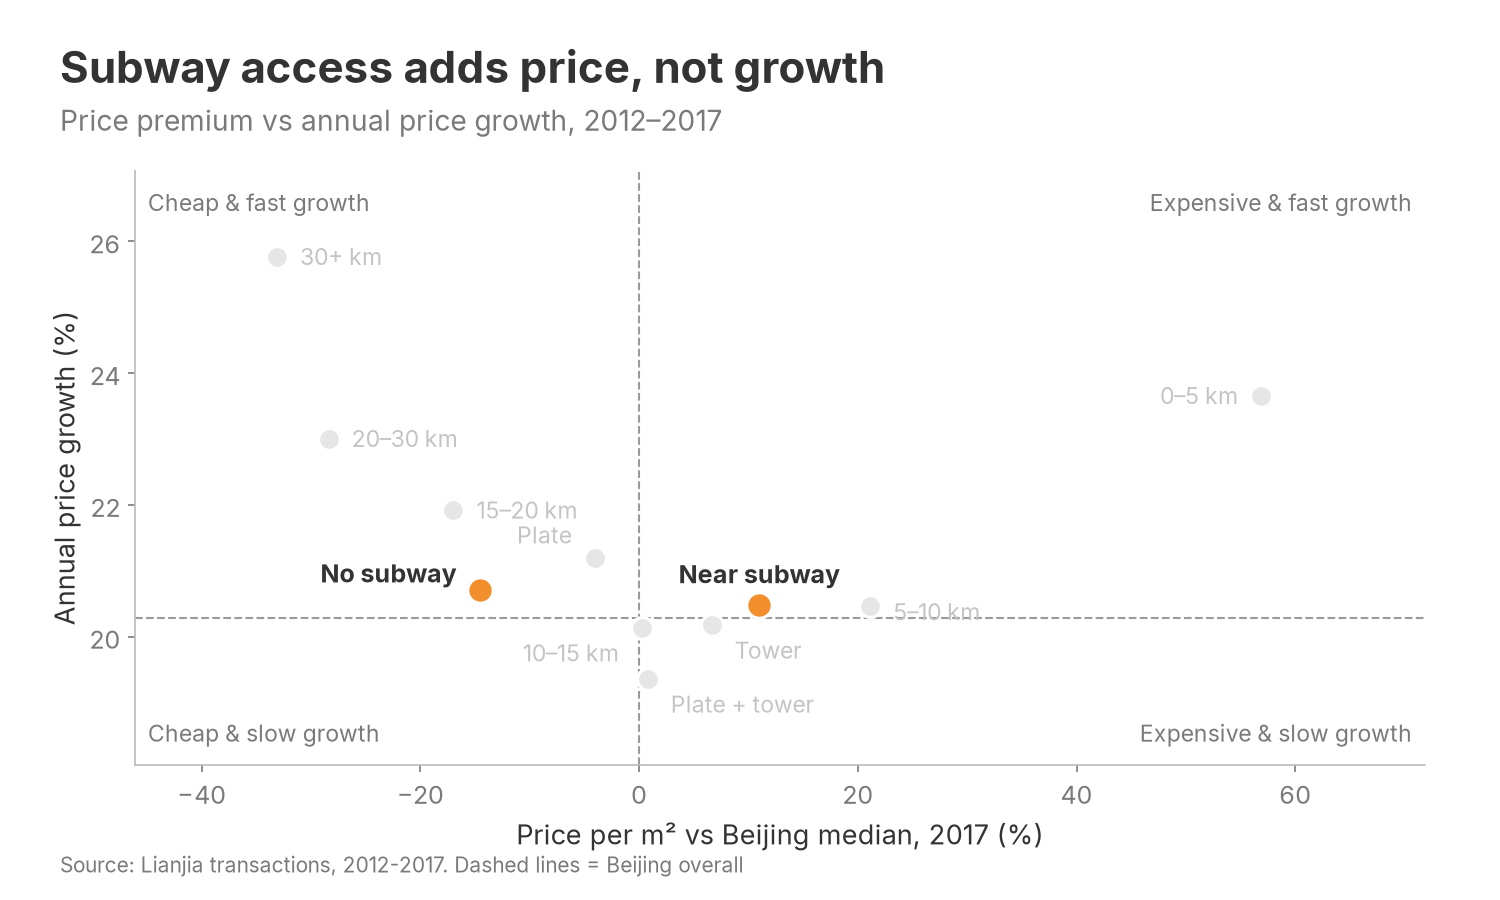

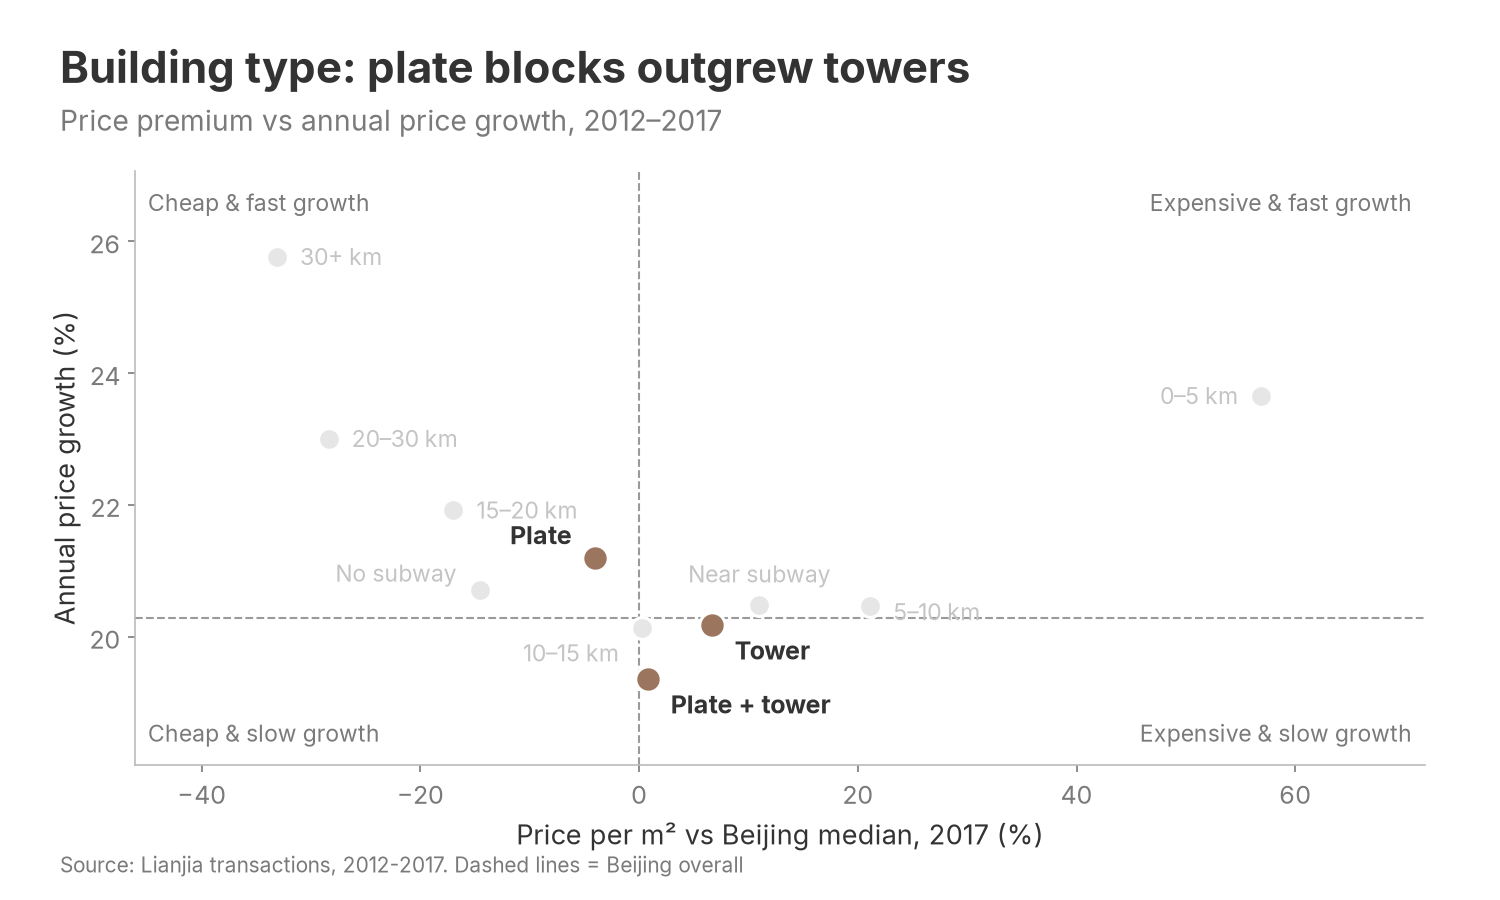

In [ ]:
def growth_table(col, data=None):
    data = df if data is None else data
    t = data.groupby([col, "trade_year"], observed=True).price.median().unstack()
    out = pd.DataFrame({"p0": t[BASE], "p1": t[END]})
    out["cagr"] = (out.p1 / out.p0) ** (1 / N_YRS) - 1
    out["n"] = data.groupby(col, observed=True).size()
    return out


overall_p1 = yearly[END]
dist, subway, btype = growth_table("band"), growth_table("subway_lab"), growth_table("btype")
FAMILIES = {"Distance to centre": (dist, bs.HIGHLIGHT), "Subway": (subway, bs.HIGHLIGHT_2), "Building type": (btype, "#9C755F")}
OFF = {"0–5 km": (-11, 0, "right"), "5–10 km": (11, -3, "left"), "10–15 km": (-11, -12, "right"),
       "15–20 km": (11, 0, "left"), "20–30 km": (11, 0, "left"), "30+ km": (11, 0, "left"),
       "Near subway": (0, 15, "center"), "No subway": (-11, 8, "right"),
       "Tower": (11, -12, "left"), "Plate": (-11, 11, "right"), "Plate + tower": (11, -12, "left")}
SPOT_TITLES = {None: "Fringe homes are the cheap, fast-growth pick",
               "Distance to centre": "Distance: the fringe and the core grew fastest",
               "Subway": "Subway access adds price, not growth",
               "Building type": "Building type: plate blocks outgrew towers"}
P = pd.DataFrame([dict(fam=fam, lab=lab, x=(r.p1 / overall_p1 - 1) * 100, y=r.cagr * 100, col=col)
                  for fam, (tab, col) in FAMILIES.items() for lab, r in tab.iterrows()])


def quadrant(spot, fname):
    fig, ax = bs.new_chart(SPOT_TITLES[spot], f"Price premium vs annual price growth, {BASE}–{END}")
    ax.axhline(overall_cagr * 100, color="#9A9A9A", lw=1, ls="--", zorder=1)
    ax.axvline(0, color="#9A9A9A", lw=1, ls="--", zorder=1)
    for _, p in P.iterrows():
        on = spot is None or p.fam == spot
        ax.scatter(p.x, p.y, s=150 if on else 110, color=p.col if on else bs.FADE,   # group keeps its own colour
                   edgecolor="white", lw=1.5, zorder=3 if on else 2)
        dx, dy, ha = OFF[p.lab]
        ax.annotate(p.lab, (p.x, p.y), xytext=(dx, dy), textcoords="offset points", ha=ha, va="center",
                    fontsize=12 if on else 11, color=bs.INK if on else bs.FADE_TEXT,
                    fontweight="bold" if (on and spot) else "normal")
    ax.set_xlim(P.x.min() - 13, P.x.max() + 15)
    ax.set_ylim(P.y.min() - 1.3, P.y.max() + 1.3)
    q = dict(transform=ax.transAxes, fontsize=11, color=bs.MUTED)
    ax.text(0.01, 0.97, "Cheap & fast growth", ha="left", va="top", **q)
    ax.text(0.99, 0.97, "Expensive & fast growth", ha="right", va="top", **q)
    ax.text(0.01, 0.03, "Cheap & slow growth", ha="left", va="bottom", **q)
    ax.text(0.99, 0.03, "Expensive & slow growth", ha="right", va="bottom", **q)
    ax.set_xlabel(f"Price per m² vs Beijing median, {END} (%)")
    ax.set_ylabel("Annual price growth (%)")
    if spot is None:
        for fam, (_, col) in FAMILIES.items():
            ax.scatter([], [], color=col, s=70, label=fam)
        ax.legend(loc="upper center", ncol=3, fontsize=10.5, handletextpad=0.3, columnspacing=1.2, bbox_to_anchor=(0.5, 1.03))
    bs.finish(fig, f"{OUT}/{fname}", SRC + ". Dashed lines = Beijing overall")
    show(f"{OUT}/{fname}")


quadrant(None, "P1_premium_vs_growth.png")
quadrant("Distance to centre", "P1a_premium_vs_growth_distance.png")
quadrant("Subway", "P1b_premium_vs_growth_subway.png")
quadrant("Building type", "P1c_premium_vs_growth_building_type.png")

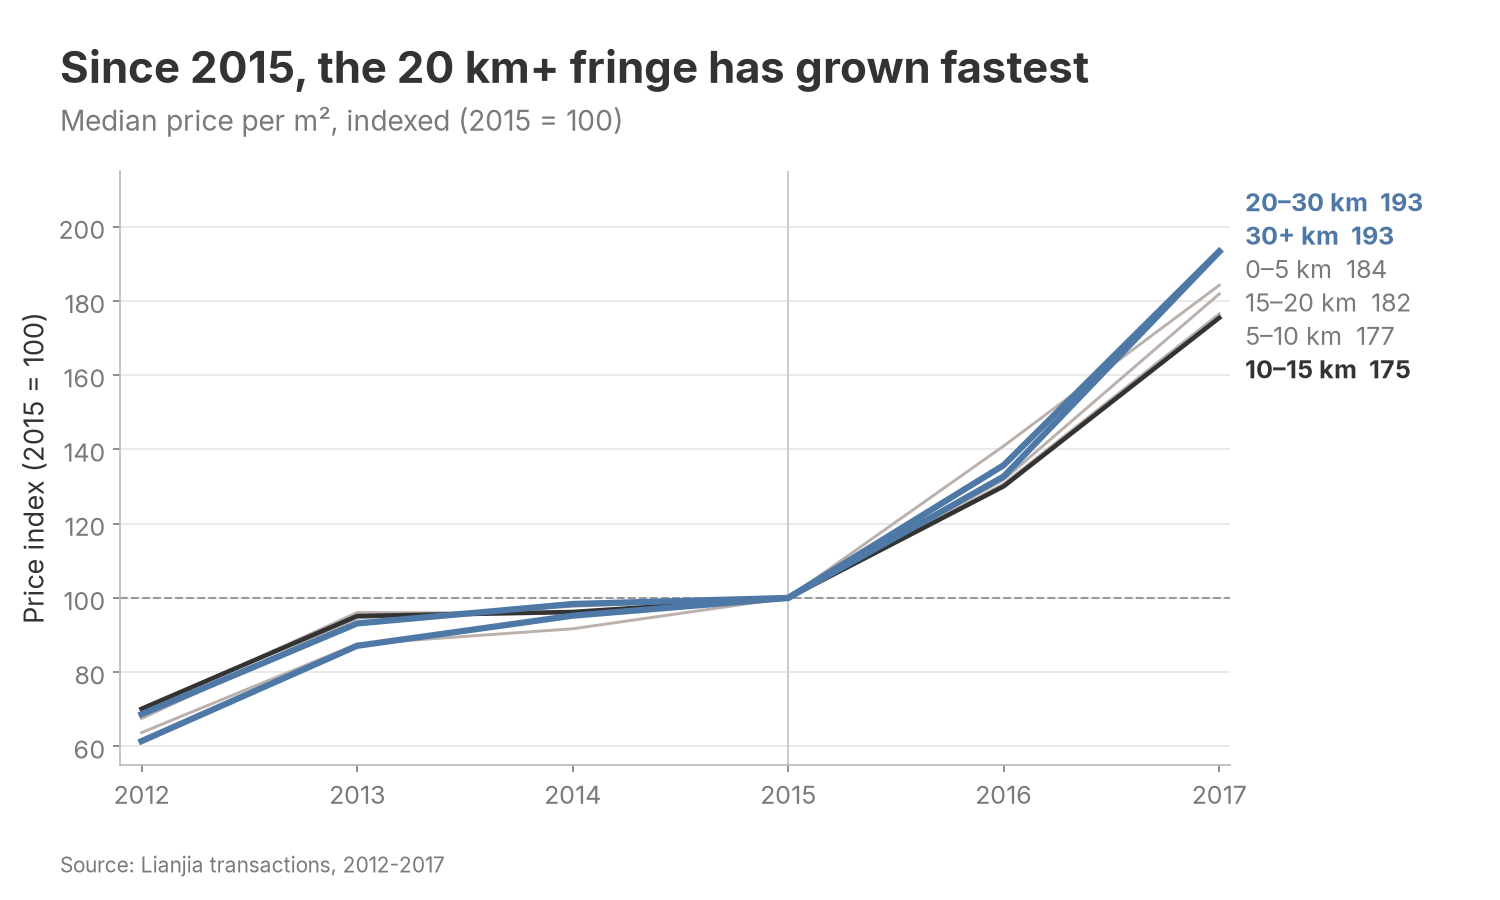

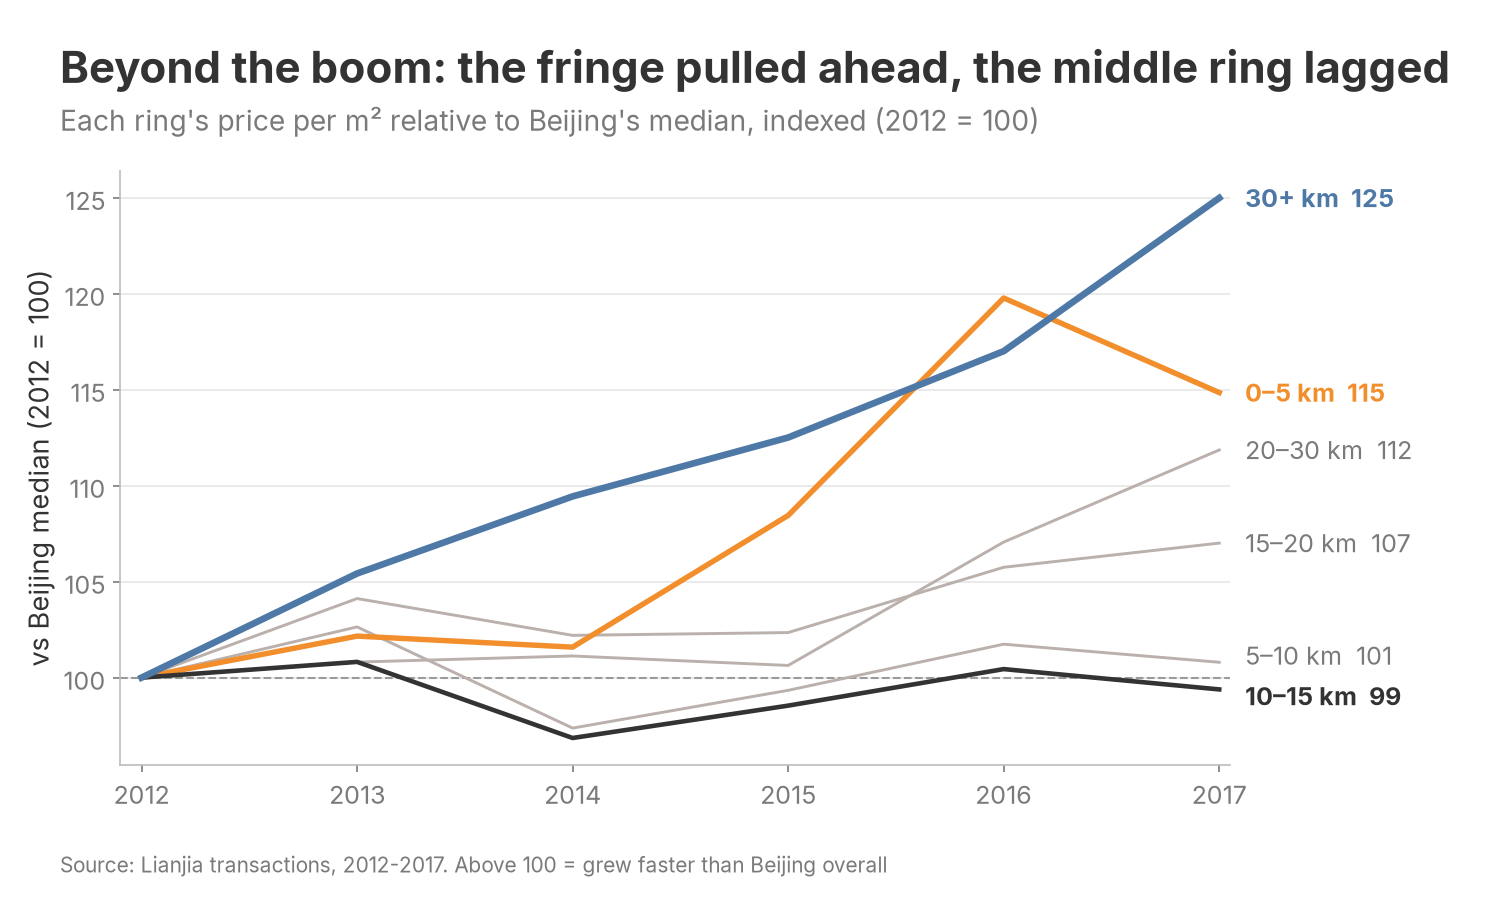

In [ ]:
t_band = df.groupby(["band", "trade_year"], observed=True).price.median().unstack()[YEARS]
LINE_STYLE = {"30+ km": (bs.HIGHLIGHT, 3.2), "0–5 km": (bs.HIGHLIGHT_2, 2.6), "10–15 km": (bs.INK, 2.2)}


def index_chart(idx, title, subtitle, ylabel, gap=None, styles=LINE_STYLE, ref_line=None):
    fig, ax = bs.new_chart(title, subtitle, rect=(0.08, 0.15, 0.74, 0.66))
    if ref_line is not None:
        ax.axhline(ref_line, color="#9A9A9A", lw=1, ls="--", zorder=1)
    for b in idx.index:
        c, w = styles.get(b, (bs.CONTEXT, 1.4))
        ax.plot(YEARS, idx.loc[b], color=c, lw=w, zorder=3 if b in styles else 2)
    ends = idx[END].values
    span = idx.values.max() - idx.values.min()
    for b, y_end, y_lab in zip(idx.index, ends, bs.spread_labels(list(ends), min_gap=gap or span * 0.075)):
        c, _ = styles.get(b, (bs.MUTED, 0))
        ax.text(END + 0.12, y_lab, f"{b}  {y_end:.0f}", va="center", fontsize=12, color=c,
                fontweight="bold" if b in styles else "normal")
    ax.set_xticks(YEARS)
    ax.set_xlim(BASE - 0.1, END + 0.05)
    ax.set_ylabel(ylabel)
    bs.ygrid(ax)
    return fig, ax


idx15 = t_band.div(t_band[2015], axis=0) * 100
fig, ax = index_chart(idx15, "Since 2015, the 20 km+ fringe has grown fastest", "Median price per m², indexed (2015 = 100)",
                      "Price index (2015 = 100)", gap=9, ref_line=100,
                      styles={"30+ km": (bs.HIGHLIGHT, 3), "20–30 km": (bs.HIGHLIGHT, 3), "10–15 km": (bs.INK, 2.2)})
ax.axvline(2015, color="#CCCCCC", lw=1, zorder=1)
ax.set_ylim(55, 215)
bs.finish(fig, f"{OUT}/P2a_indexed_growth_base2015.png", SRC)
show(f"{OUT}/P2a_indexed_growth_base2015.png")

rel = t_band.div(yearly[YEARS], axis=1)
rel = rel.div(rel[BASE], axis=0) * 100
fig, ax = index_chart(rel, "Beyond the boom: the fringe pulled ahead, the middle ring lagged",
                      f"Each ring's price per m² relative to Beijing's median, indexed ({BASE} = 100)",
                      "vs Beijing median (2012 = 100)", ref_line=100)
bs.finish(fig, f"{OUT}/P2b_growth_vs_beijing_by_distance.png", SRC + ". Above 100 = grew faster than Beijing overall")
show(f"{OUT}/P2b_growth_vs_beijing_by_distance.png")

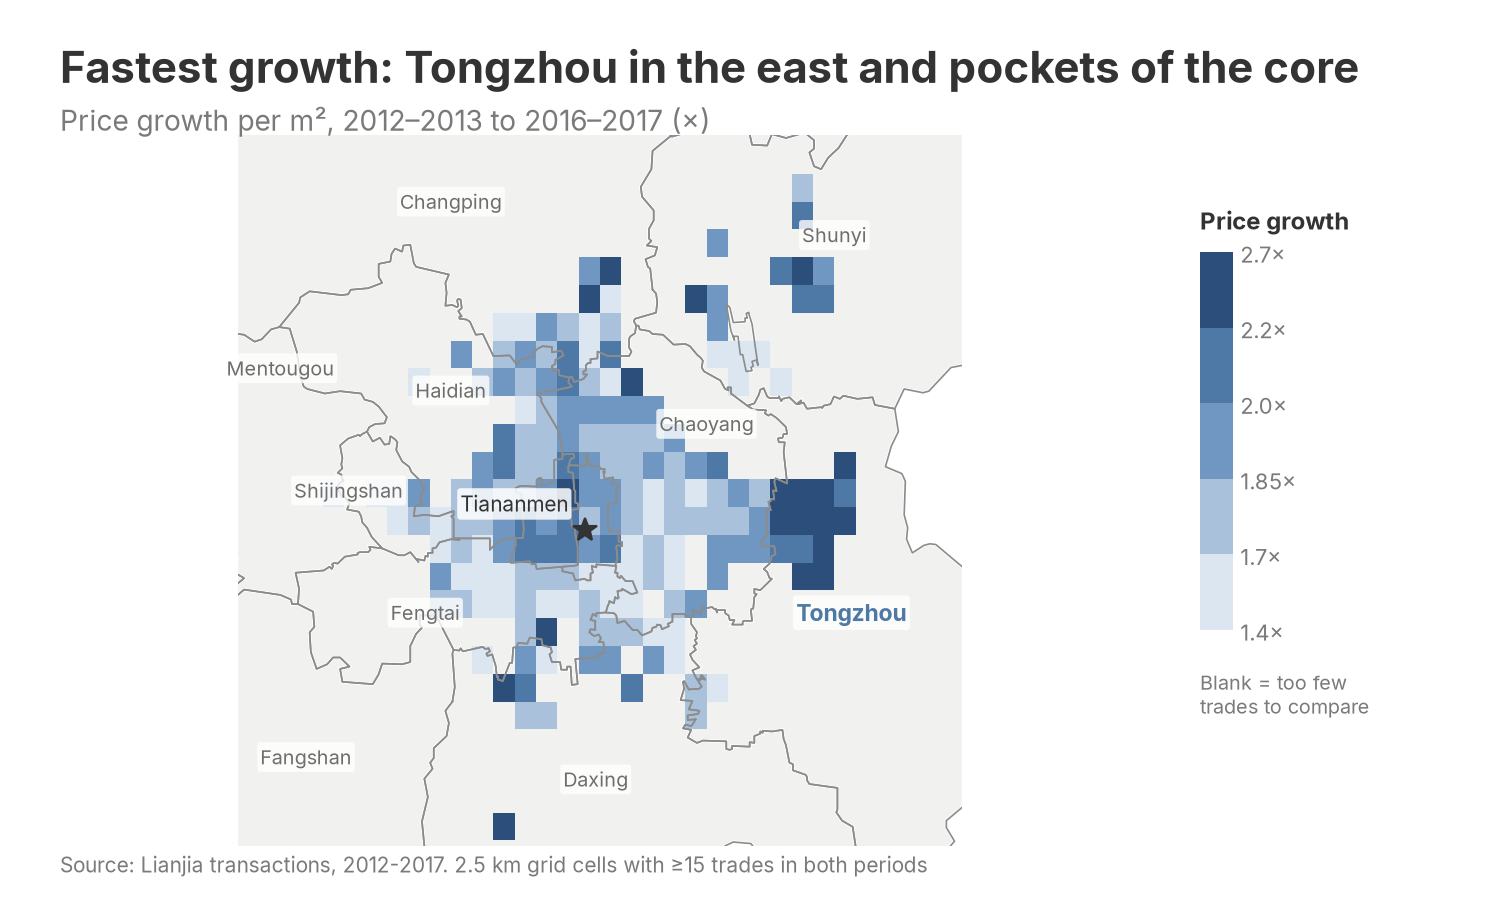

In [ ]:
# P3 growth map on district basemap
cell = 0.025
m_ = df.copy()
m_["gx"] = np.floor(m_.Lng / cell) * cell
m_["gy"] = np.floor(m_.Lat / cell) * cell
m_["period"] = np.where(m_.trade_year <= BASE + 1, "early", np.where(m_.trade_year >= END - 1, "late", None))
g = m_.dropna(subset=["period"]).groupby(["gx", "gy", "period"]).price.agg(["median", "size"]).unstack()
g = g[(g[("size", "early")] >= 15) & (g[("size", "late")] >= 15)]
g["growth"] = g[("median", "late")] / g[("median", "early")]
g = g.reset_index()
XLIM, YLIM = (116.0, 116.85), (39.62, 40.26)


def basemap(ax, labels):
    for geom in polys.values():
        for gg in (geom.geoms if geom.geom_type == "MultiPolygon" else [geom]):
            x, y = gg.exterior.xy
            ax.fill(x, y, facecolor="#F1F1EF", edgecolor="white", lw=1.6, zorder=1)
    for nm, (x, y, hot) in labels.items():
        ax.text(x, y, nm, fontsize=11 if hot else 9.5, ha="center", va="center", zorder=6,
                color=bs.HIGHLIGHT if hot else "#6E6E6E", fontweight="bold" if hot else "normal",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))


def outlines(ax):
    for geom in polys.values():
        for gg in (geom.geoms if geom.geom_type == "MultiPolygon" else [geom]):
            x, y = gg.exterior.xy
            ax.plot(x, y, color="#8C8C8C", lw=0.8, zorder=3)


MAP_LABELS = {"Haidian": (116.25, 40.03, 0), "Chaoyang": (116.55, 40.0, 0), "Fengtai": (116.22, 39.83, 0),
              "Shijingshan": (116.13, 39.94, 0), "Tongzhou": (116.72, 39.83, 1), "Daxing": (116.42, 39.68, 0),
              "Changping": (116.25, 40.2, 0), "Shunyi": (116.7, 40.17, 0), "Fangshan": (116.08, 39.7, 0),
              "Mentougou": (116.05, 40.05, 0)}
fig, ax = bs.new_chart("Fastest growth: Tongzhou in the east and pockets of the core",
                       f"Price growth per m², {BASE}–{BASE+1} to {END-1}–{END} (×)", rect=(0.02, 0.06, 0.76, 0.79))
basemap(ax, MAP_LABELS)
cmap = LinearSegmentedColormap.from_list("blues", bs.SEQ_BLUES)
bounds = [1.4, 1.7, 1.85, 2.0, 2.2, 2.7]
xs_ = np.round(np.arange(XLIM[0] - cell, XLIM[1] + cell, cell) / cell) * cell
ys_ = np.round(np.arange(YLIM[0] - cell, YLIM[1] + cell, cell) / cell) * cell
Z = np.full((len(ys_), len(xs_)), np.nan)
xi = np.round((g.gx - xs_[0]) / cell).astype(int)
yi = np.round((g.gy - ys_[0]) / cell).astype(int)
ok = (xi >= 0) & (xi < len(xs_)) & (yi >= 0) & (yi < len(ys_))
Z[yi[ok], xi[ok]] = g.growth[ok]
mesh = ax.pcolormesh(np.append(xs_, xs_[-1] + cell), np.append(ys_, ys_[-1] + cell), Z, cmap=cmap,
                     norm=BoundaryNorm(bounds, cmap.N), edgecolors="none", zorder=2)
outlines(ax)
ax.plot(*CENTRE, marker="*", color=bs.INK, ms=12, zorder=6)
ax.annotate("Tiananmen", CENTRE, xytext=(-8, 9), textcoords="offset points", fontsize=10, ha="right", zorder=6,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
ax.set_xlim(*XLIM); ax.set_ylim(*YLIM)
ax.set_aspect(1 / np.cos(np.radians(CENTRE[1])))
ax.axis("off")
cax = fig.add_axes([0.8, 0.3, 0.022, 0.42])
cb = fig.colorbar(mesh, cax=cax, ticks=bounds)
cb.ax.set_yticklabels([f"{b}×" for b in bounds])
cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=10.5, length=0)
fig.text(0.8, 0.745, "Price growth", fontsize=11.5, fontweight="bold")
fig.text(0.8, 0.255, "Blank = too few\ntrades to compare", fontsize=9.5, color=bs.MUTED, va="top")
bs.finish(fig, f"{OUT}/P3_growth_map.png", SRC + ". 2.5 km grid cells with ≥15 trades in both periods")
show(f"{OUT}/P3_growth_map.png")

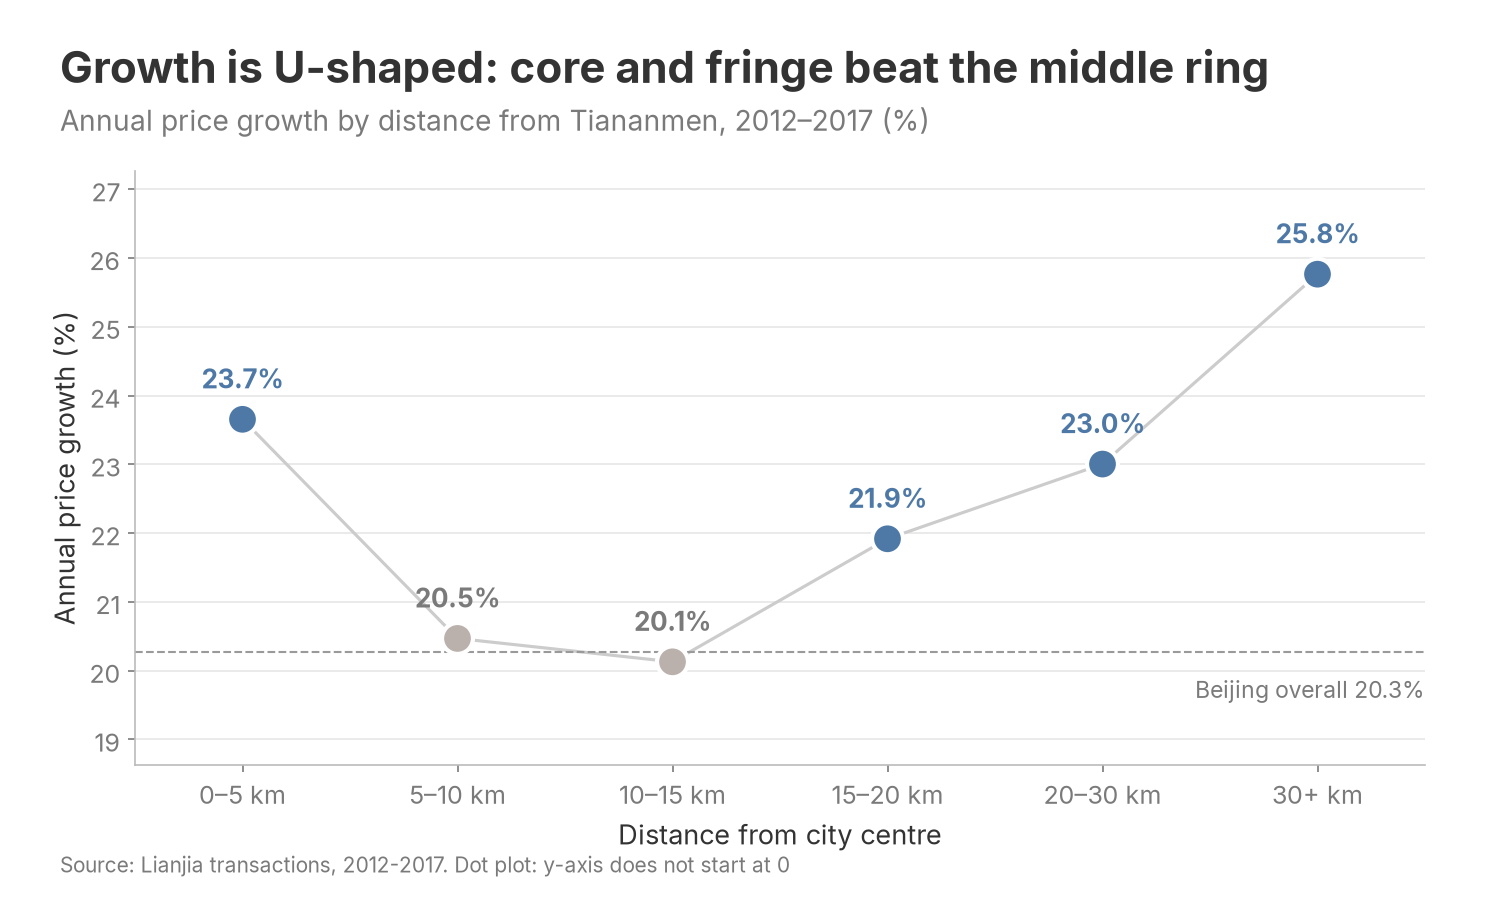

In [ ]:
# P4 U-shape dot plot
fig, ax = bs.new_chart("Growth is U-shaped: core and fringe beat the middle ring",
                       f"Annual price growth by distance from Tiananmen, {BASE}–{END} (%)")
y = dist.cagr.values * 100
cols = [bs.HIGHLIGHT if v > overall_cagr * 100 + 1 else bs.CONTEXT for v in y]
ax.plot(range(len(y)), y, color="#CCCCCC", lw=1.5, zorder=1)
ax.scatter(range(len(y)), y, s=220, color=cols, edgecolor="white", lw=2, zorder=3)
for i, v in enumerate(y):
    ax.text(i, v + 0.45, f"{v:.1f}%", ha="center", fontsize=12.5, fontweight="bold",
            color=bs.HIGHLIGHT if cols[i] == bs.HIGHLIGHT else bs.MUTED)
ax.axhline(overall_cagr * 100, color="#9A9A9A", lw=1, ls="--")
ax.text(len(y) - 0.5, overall_cagr * 100 - 0.35, f"Beijing overall {overall_cagr*100:.1f}%", ha="right", va="top",
        fontsize=11, color=bs.MUTED)
ax.set_xticks(range(len(y)), BANDS)
ax.set_xlim(-0.5, len(y) - 0.5)
ax.set_ylim(y.min() - 1.5, y.max() + 1.5)
ax.set_ylabel("Annual price growth (%)")
ax.set_xlabel("Distance from city centre")
bs.ygrid(ax)
bs.finish(fig, f"{OUT}/P4_growth_by_distance_dotplot.png", SRC + ". Dot plot: y-axis does not start at 0")
show(f"{OUT}/P4_growth_by_distance_dotplot.png")

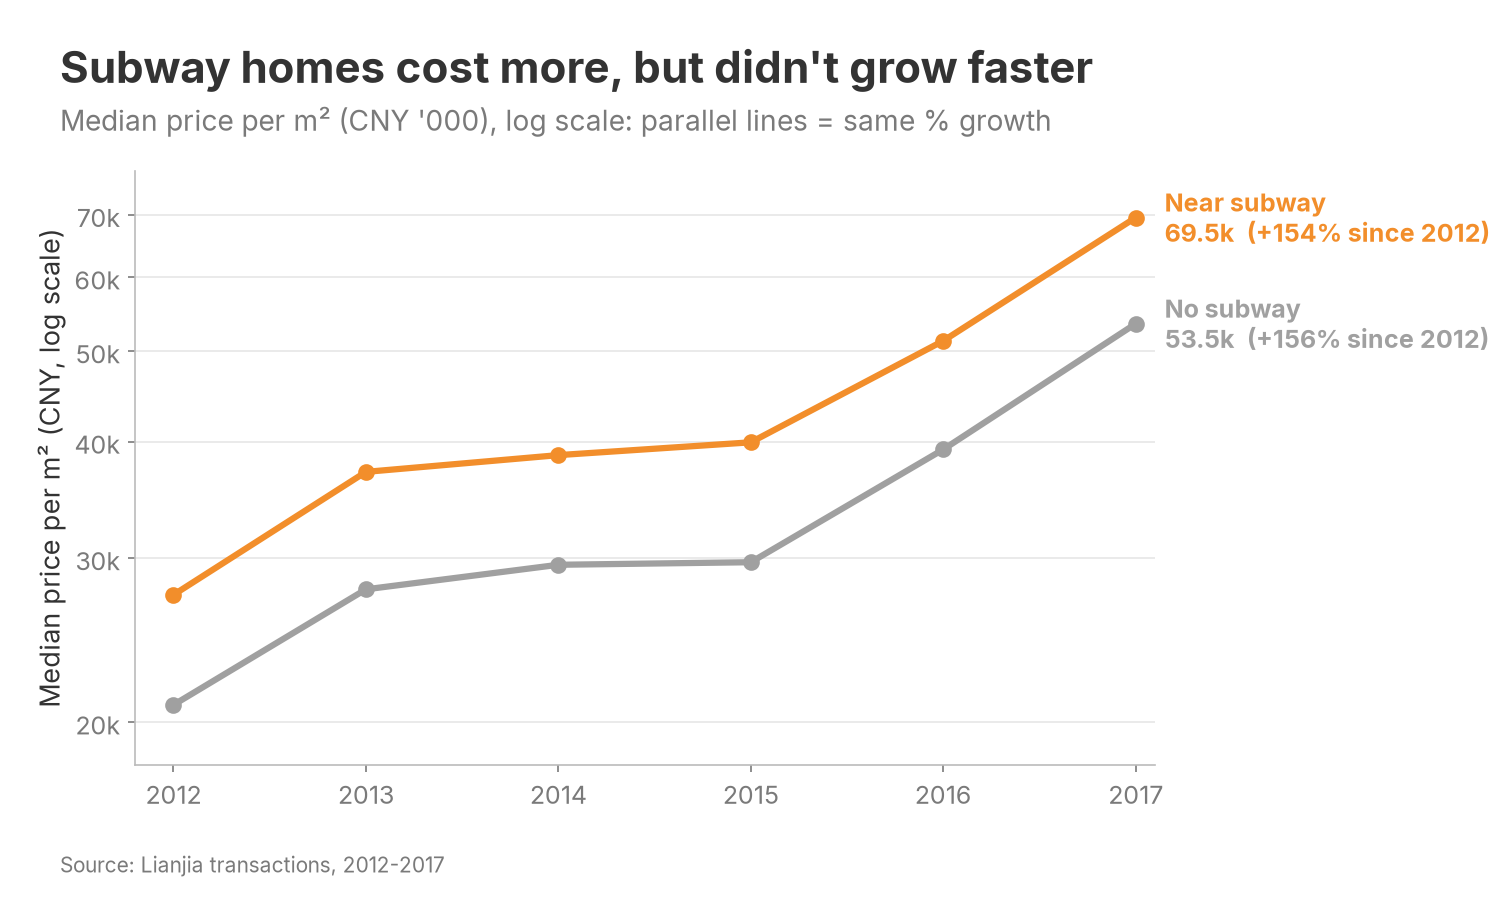

In [ ]:
# P5 subway over time
ts = df.groupby(["subway_lab", "trade_year"]).price.median().unstack()[YEARS] / 1000
fig, ax = bs.new_chart("Subway homes cost more, but didn't grow faster",
                       "Median price per m² (CNY '000), log scale: parallel lines = same % growth", rect=(0.09, 0.15, 0.68, 0.66))
for lab, c in [("Near subway", bs.HIGHLIGHT_2), ("No subway", "#A0A0A0")]:
    s = ts.loc[lab]
    ax.plot(YEARS, s.values, color=c, lw=3, marker="o", ms=7, zorder=3)
    ax.text(END + 0.15, s[END], f"{lab}\n{s[END]:.1f}k  (+{(s[END]/s[BASE]-1)*100:.0f}% since {BASE})",
            va="center", fontsize=12, color=c, fontweight="bold")
ax.set_yscale("log")
ticks = [20, 30, 40, 50, 60, 70]
ax.yaxis.set_major_locator(FixedLocator(ticks))
ax.yaxis.set_minor_locator(NullLocator())
ax.set_yticklabels([f"{v}k" for v in ticks])
ax.set_ylim(18, 78)
ax.set_xticks(YEARS)
ax.set_xlim(BASE - 0.2, END + 0.1)
ax.set_ylabel("Median price per m² (CNY, log scale)")
bs.ygrid(ax)
bs.finish(fig, f"{OUT}/P5_subway_over_time.png", SRC)
show(f"{OUT}/P5_subway_over_time.png")

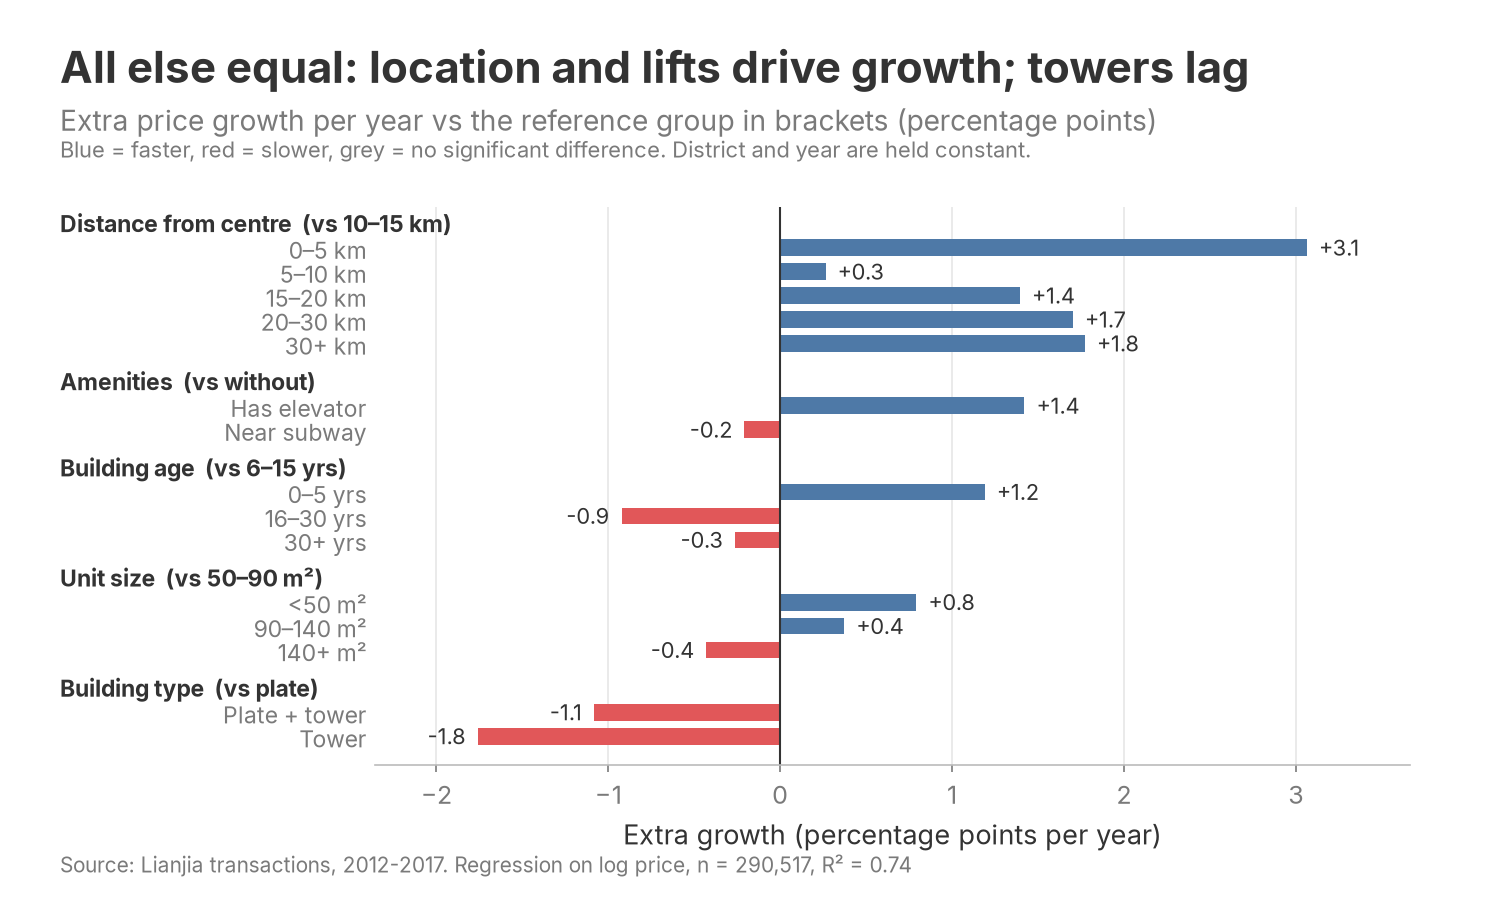

In [ ]:
# P6 growth drivers regression: log(price) = year FE + district FE + traits + trait x (years since 2012)
# The trait x time coefficient = extra annual growth vs the reference group, other traits/district/year held constant.
m = df.dropna(subset=["band", "btype", "size_category", "age_bucket"]).copy()
m["t"] = m.trade_year - BASE
REF = {"band": "10–15 km", "btype": "Plate", "size_category": "50-90", "age_bucket": "6-15"}
feat = pd.DataFrame({"subway": m.subway, "elevator": m.elevator}, index=m.index).astype(float)
for col, ref in REF.items():
    dm = pd.get_dummies(m[col].astype(str), prefix=col, prefix_sep="=", dtype=float).drop(columns=f"{col}={ref}")
    feat = pd.concat([feat, dm], axis=1)
fe = pd.concat([pd.get_dummies(m.trade_year, prefix="yr", drop_first=True, dtype=float),
                pd.get_dummies(m.district, prefix="dist", drop_first=True, dtype=float)], axis=1)
X = pd.concat([pd.Series(1.0, index=m.index, name="const"), fe, feat, feat.mul(m.t.values, axis=0).add_suffix(" x t")], axis=1)
Xv, yv = X.values, np.log(m.price.values)
beta, *_ = np.linalg.lstsq(Xv, yv, rcond=None)
resid = yv - Xv @ beta
XtX_inv = np.linalg.inv(Xv.T @ Xv)
V = XtX_inv @ ((Xv * resid[:, None] ** 2).T @ Xv) @ XtX_inv * len(yv) / (len(yv) - Xv.shape[1])   # HC1 robust
coef = pd.DataFrame({"beta": beta, "se": np.sqrt(np.diag(V))}, index=X.columns)
r2 = 1 - resid.var() / yv.var()
GROUPS = [("Distance from centre  (vs 10–15 km)", [("band=0–5 km", "0–5 km"), ("band=5–10 km", "5–10 km"),
           ("band=15–20 km", "15–20 km"), ("band=20–30 km", "20–30 km"), ("band=30+ km", "30+ km")]),
          ("Amenities  (vs without)", [("elevator", "Has elevator"), ("subway", "Near subway")]),
          ("Building age  (vs 6–15 yrs)", [("age_bucket=0-5", "0–5 yrs"), ("age_bucket=16-30", "16–30 yrs"), ("age_bucket=30+", "30+ yrs")]),
          ("Unit size  (vs 50–90 m²)", [("size_category=<50", "<50 m²"), ("size_category=90-140", "90–140 m²"), ("size_category=140+", "140+ m²")]),
          ("Building type  (vs plate)", [("btype=Plate + tower", "Plate + tower"), ("btype=Tower", "Tower")])]
rows, heads, yc = [], [], 0
for head, items in GROUPS:
    heads.append((yc, head)); yc += 1
    for key, lab in items:
        b, se = coef.loc[f"{key} x t"]
        rows.append(dict(lab=lab, pp=(np.exp(b) - 1) * 100, sig=abs(b / se) > 1.96, y=yc)); yc += 1
    yc += 0.6
R = pd.DataFrame(rows)
fig, ax = bs.new_chart("All else equal: location and lifts drive growth; towers lag",
                       "Extra price growth per year vs the reference group in brackets (percentage points)",
                       rect=(0.25, 0.15, 0.69, 0.62))
cols = [bs.CONTEXT if not s else (bs.HIGHLIGHT if v > 0 else bs.NEGATIVE) for v, s in zip(R.pp, R.sig)]
ax.barh(R.y, R.pp, color=cols, height=0.7)
for _, r in R.iterrows():
    ax.text(r.pp + (0.07 if r.pp >= 0 else -0.07), r.y, f"{r.pp:+.1f}", va="center",
            ha="left" if r.pp >= 0 else "right", fontsize=10.5, color=bs.INK if r.sig else bs.MUTED)
ax.set_yticks(R.y, R.lab)
tr = blended_transform_factory(fig.transFigure, ax.transData)
for yh, head in heads:
    ax.text(0.04, yh, head, transform=tr, ha="left", va="center", fontsize=11, fontweight="bold")
ax.tick_params(axis="y", labelsize=11, length=0, pad=4)
ax.axvline(0, color=bs.INK, lw=1)
ax.set_ylim(yc - 0.4, -0.7)
ax.set_xlim(R.pp.min() - 0.6, R.pp.max() + 0.6)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Extra growth (percentage points per year)")
bs.xgrid(ax)
fig.text(0.04, 0.825, "Blue = faster, red = slower, grey = no significant difference. District and year are held constant.",
         fontsize=10.5, color=bs.MUTED)
bs.finish(fig, f"{OUT}/P6_growth_drivers.png", f"{SRC}. Regression on log price, n = {len(m):,}, R² = {r2:.2f}")
show(f"{OUT}/P6_growth_drivers.png")

## P2. Which districts show the strongest and most consistent appreciation?
Fangshan is excluded from growth rankings: it has only 1-2 trades a year before 2015, so a 2012 base is meaningless.

In [ ]:
dist_year = df.groupby(["dname", "trade_year"]).price.median().unstack()[YEARS]
dist_n = df.groupby(["dname", "trade_year"]).size().unstack()[YEARS]
print(dist_n)
valid = dist_n[[BASE, END]].min(axis=1) >= 100
dcagr = ((dist_year[END] / dist_year[BASE]) ** (1 / N_YRS) - 1)[valid].sort_values() * 100
print("excluded (<100 trades in 2012 or 2017):", list(valid[~valid].index))

trade_year    2012   2013  2014   2015   2016   2017
dname                                               
Changping     3647   4094  3142   7095  11553   5508
Chaoyang     11509  11834  9899  21953  29684  14244
Daxing        1732   1927  1281   2772   4170   2160
Dongcheng     1676   1650  1661   3995   4352   2195
Fangshan         1      2     1    437   1448    730
Fengtai       3400   3334  2637   5564   7968   3918
Haidian       4410   4039  4193   7913   9398   4673
Mentougou      122    142   107    280    464    259
Shijingshan   1371   1360  1220   2000   2831   1356
Shunyi        1292   1371   918   1805   2170   1089
Tongzhou      1543   2198  1230   2817   2440   1652
Xicheng       3435   3235  3517   7051   7615   3776
Yizhuang       138    259   148    373    922    348
excluded (<100 trades in 2012 or 2017): ['Fangshan']


**PD1. Highest growth in median price per m²**

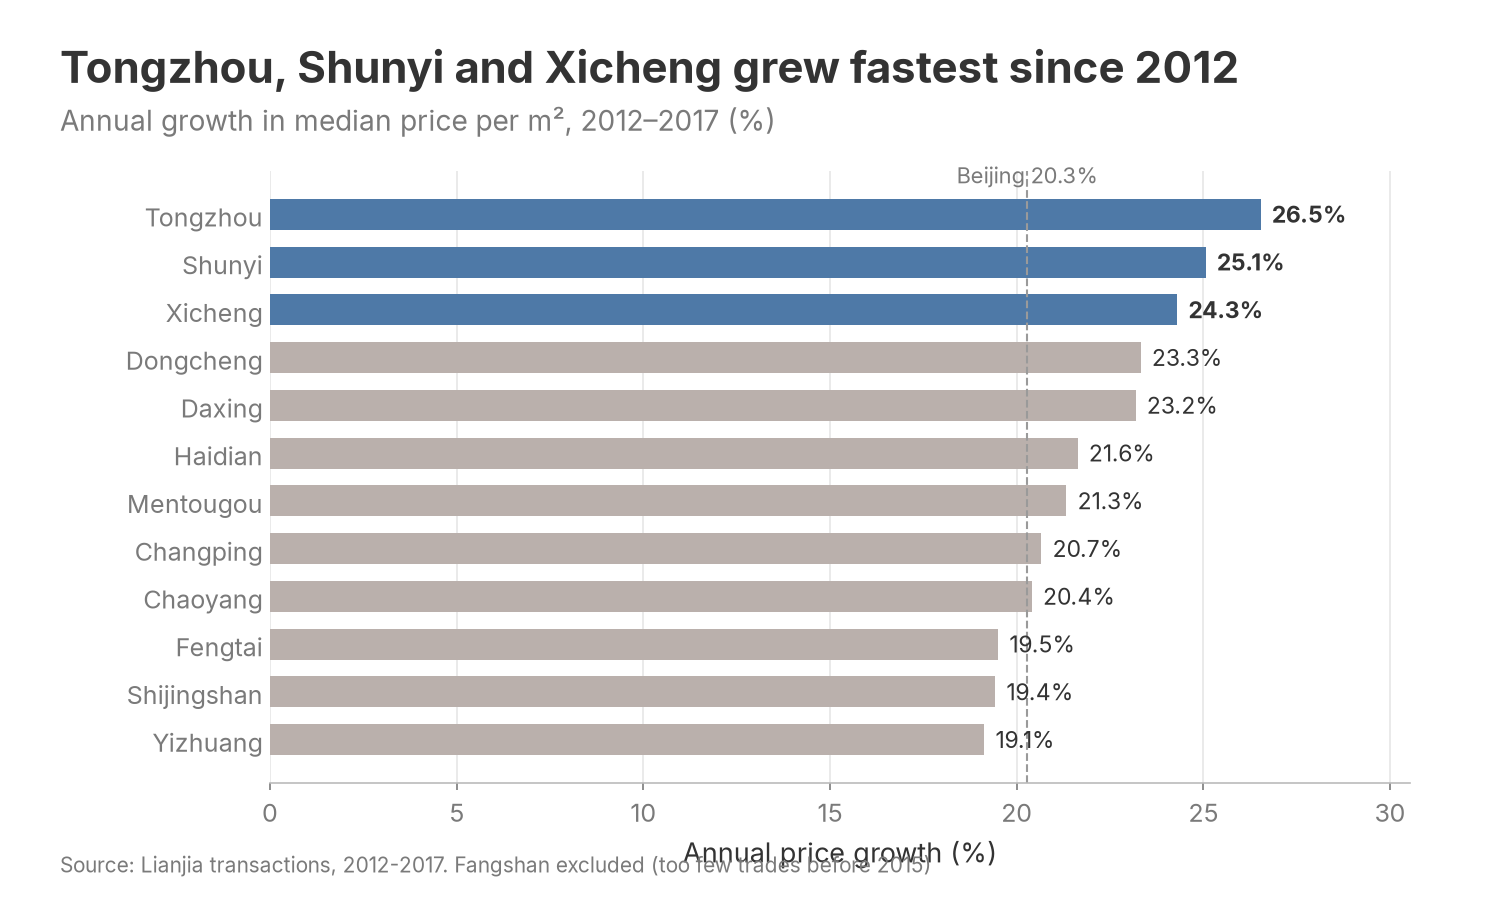

In [ ]:
top3 = dcagr.index[-3:]
fig, ax = bs.new_chart(f"{', '.join(top3[::-1][:2])} and {top3[0]} grew fastest since 2012",
                       f"Annual growth in median price per m², {BASE}–{END} (%)", rect=(0.18, 0.13, 0.76, 0.68))
cols = [bs.HIGHLIGHT if d in top3 else bs.CONTEXT for d in dcagr.index]
ax.barh(dcagr.index, dcagr.values, color=cols, height=0.65)
for i, v in enumerate(dcagr.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=11, color=bs.INK,
            fontweight="bold" if cols[i] == bs.HIGHLIGHT else "normal")
ax.axvline(overall_cagr * 100, color="#9A9A9A", lw=1, ls="--")
ax.text(overall_cagr * 100, len(dcagr) - 0.35, f"Beijing {overall_cagr*100:.1f}%", ha="center", fontsize=10.5, color=bs.MUTED)
ax.set_xlim(0, dcagr.max() + 4)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Annual price growth (%)")
bs.xgrid(ax)
bs.finish(fig, f"{OUT}/PD1_district_growth.png", SRC + ". Fangshan excluded (too few trades before 2015)")
show(f"{OUT}/PD1_district_growth.png")

**PD2. Was growth consistent or concentrated in one year?**

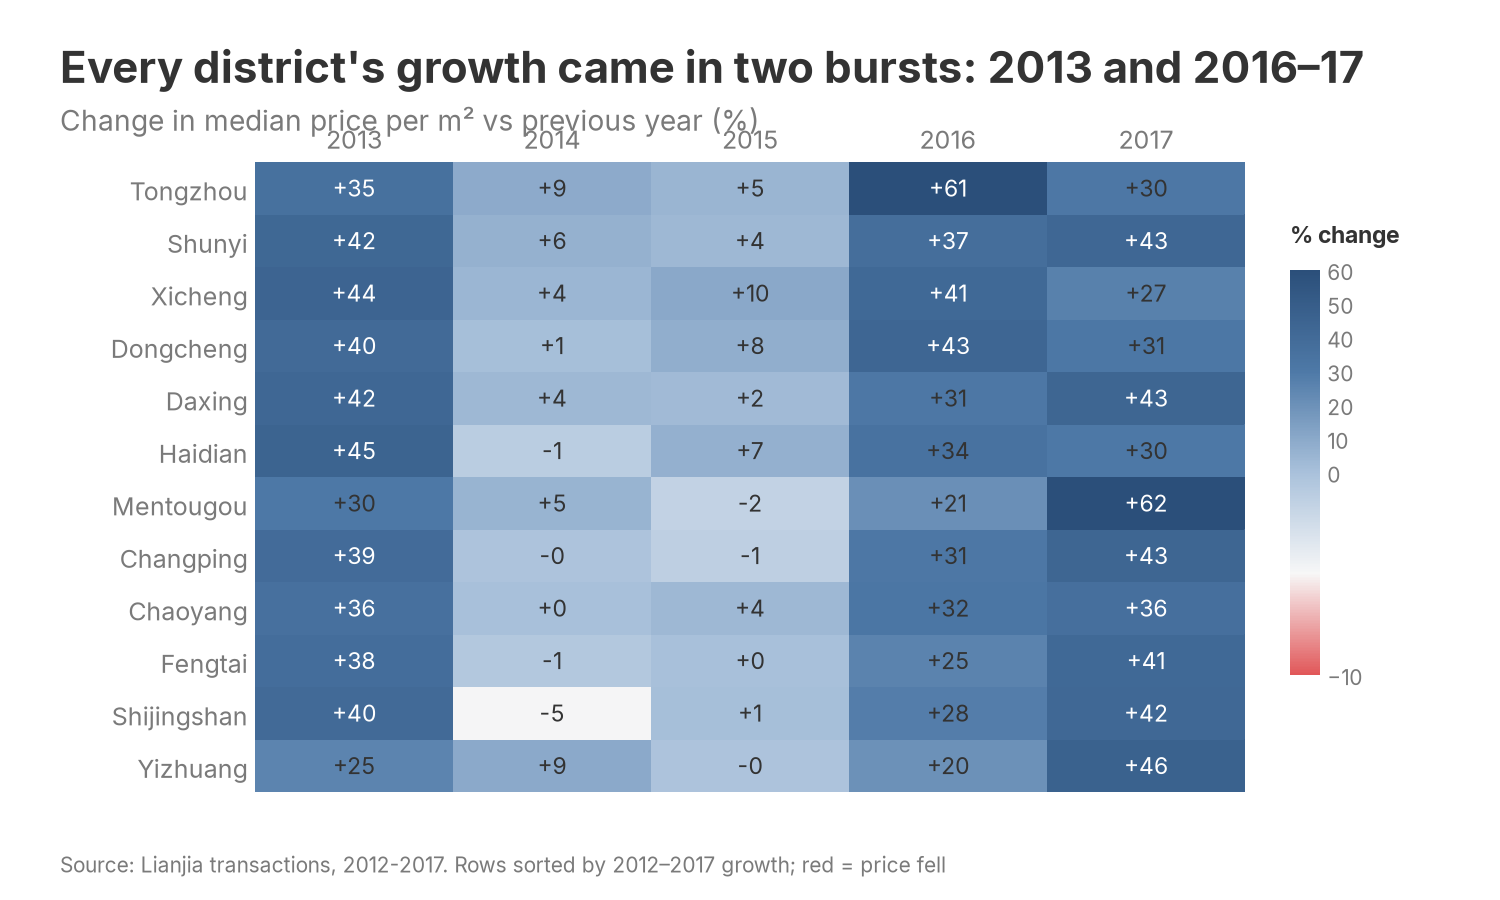

In [ ]:
yoy_d = (dist_year.pct_change(axis=1) * 100).loc[dcagr.index[::-1], YEARS[1:]]
best_year_share = yoy_d.div(yoy_d.clip(lower=0).sum(axis=1), axis=0).max(axis=1)
fig, ax = bs.new_chart("Every district's growth came in two bursts: 2013 and 2016–17",
                       "Change in median price per m² vs previous year (%)", rect=(0.17, 0.12, 0.66, 0.70))
cmap = LinearSegmentedColormap.from_list("div", [bs.NEGATIVE, "#F7F7F7", "#A9C1DB", bs.HIGHLIGHT, "#2B4F7A"])
im = ax.imshow(yoy_d.values, cmap=cmap, norm=TwoSlopeNorm(vcenter=0, vmin=-10, vmax=60), aspect="auto")
for i in range(yoy_d.shape[0]):
    for j in range(yoy_d.shape[1]):
        v = yoy_d.values[i, j]
        ax.text(j, i, f"{v:+.0f}", ha="center", va="center", fontsize=11, color="white" if v > 35 else bs.INK)
ax.set_xticks(range(yoy_d.shape[1]), [str(c) for c in yoy_d.columns])
ax.set_yticks(range(yoy_d.shape[0]), yoy_d.index)
ax.tick_params(length=0)
ax.xaxis.tick_top()
for s_ in ax.spines.values():
    s_.set_visible(False)
cax = fig.add_axes([0.86, 0.25, 0.02, 0.45])
cb = fig.colorbar(im, cax=cax)
cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=10, length=0)
fig.text(0.86, 0.73, "% change", fontsize=11, fontweight="bold")
bs.finish(fig, f"{OUT}/PD2_district_growth_by_year.png", SRC + ". Rows sorted by 2012–2017 growth; red = price fell")
show(f"{OUT}/PD2_district_growth_by_year.png")

**PD3. Does the ranking change when comparing similar property types and sizes?**
Like-for-like = 50-90 m² plate-building homes (the most common type), which removes differences in product mix.

                   all       like  r_all  r_like
dname                                           
Tongzhou     26.534535  26.139695      1       1
Shunyi       25.061805  25.122992      2       2
Xicheng      24.300117  23.537266      3       3
Dongcheng    23.321200  22.956584      4       4
Daxing       23.186063  22.689390      5       5
Haidian      21.632366  21.381503      6       7
Mentougou    21.331045  21.688841      7       6
Changping    20.660984  20.079437      8      10
Chaoyang     20.404785  20.184524      9       9
Fengtai      19.503599  19.512891     10      11
Shijingshan  19.424467  19.386758     11      12
Yizhuang     19.131979  20.261762     12       8


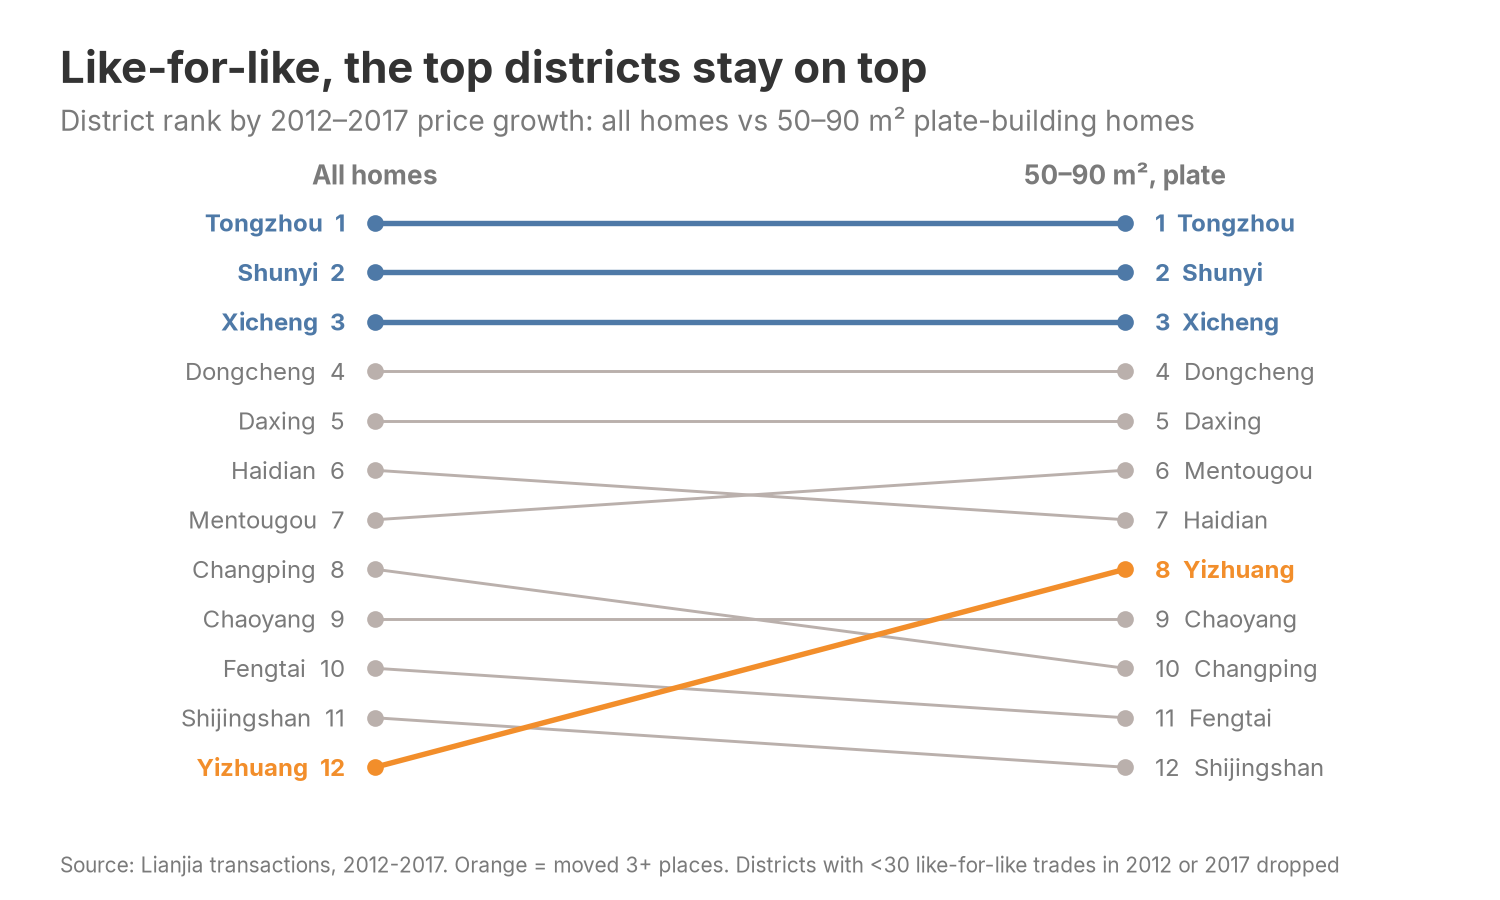

In [ ]:
like = df[(df.size_category == "50-90") & (df.btype == "Plate")]
ly = like.groupby(["dname", "trade_year"]).price.median().unstack()
ln = like.groupby(["dname", "trade_year"]).size().unstack()
ok_l = (ln[[BASE, END]].min(axis=1) >= 30) & valid
lcagr = ((ly[END] / ly[BASE]) ** (1 / N_YRS) - 1)[ok_l] * 100
both = pd.DataFrame({"all": dcagr, "like": lcagr}).dropna()
both["r_all"] = both["all"].rank(ascending=False).astype(int)
both["r_like"] = both["like"].rank(ascending=False).astype(int)
print(both.sort_values("r_all"))
moved = both[(both.r_all - both.r_like).abs() >= 3].index
fig, ax = bs.new_chart("Like-for-like, the top districts stay on top",
                       "District rank by 2012–2017 price growth: all homes vs 50–90 m² plate-building homes",
                       rect=(0.24, 0.12, 0.52, 0.66))
for d_, r in both.iterrows():
    c = bs.HIGHLIGHT if r.r_all <= 3 else (bs.HIGHLIGHT_2 if d_ in moved else bs.CONTEXT)
    lw = 2.6 if c != bs.CONTEXT else 1.4
    ax.plot([0, 1], [r.r_all, r.r_like], color=c, lw=lw, marker="o", ms=7)
    ax.text(-0.04, r.r_all, f"{d_}  {int(r.r_all)}", ha="right", va="center", fontsize=11.5,
            color=c if c != bs.CONTEXT else bs.MUTED, fontweight="bold" if c != bs.CONTEXT else "normal")
    ax.text(1.04, r.r_like, f"{int(r.r_like)}  {d_}", ha="left", va="center", fontsize=11.5,
            color=c if c != bs.CONTEXT else bs.MUTED, fontweight="bold" if c != bs.CONTEXT else "normal")
ax.set_ylim(len(both) + 0.5, 0.5)
ax.set_xlim(-0.02, 1.02)
ax.set_xticks([0, 1], ["All homes", "50–90 m², plate"], fontsize=12.5, fontweight="bold")
ax.xaxis.tick_top()
ax.set_yticks([])
for s_ in ax.spines.values():
    s_.set_visible(False)
ax.tick_params(length=0)
bs.finish(fig, f"{OUT}/PD3_district_rank_like_for_like.png",
          SRC + ". Orange = moved 3+ places. Districts with <30 like-for-like trades in 2012 or 2017 dropped")
show(f"{OUT}/PD3_district_rank_like_for_like.png")

**PD4. What sits behind district growth? (yearbook table 2-1, resident population)**

             cagr  popg
Changping    20.7  12.7
Chaoyang     20.4  -0.2
Daxing       23.2  19.8
Dongcheng    23.3  -6.3
Fengtai      19.5  -1.3
Haidian      21.6  -0.1
Mentougou    21.3   8.1
Shijingshan  19.4  -4.2
Shunyi       25.1  18.4
Tongzhou     26.5  16.8
Xicheng      24.3  -5.2 
correlation 0.46


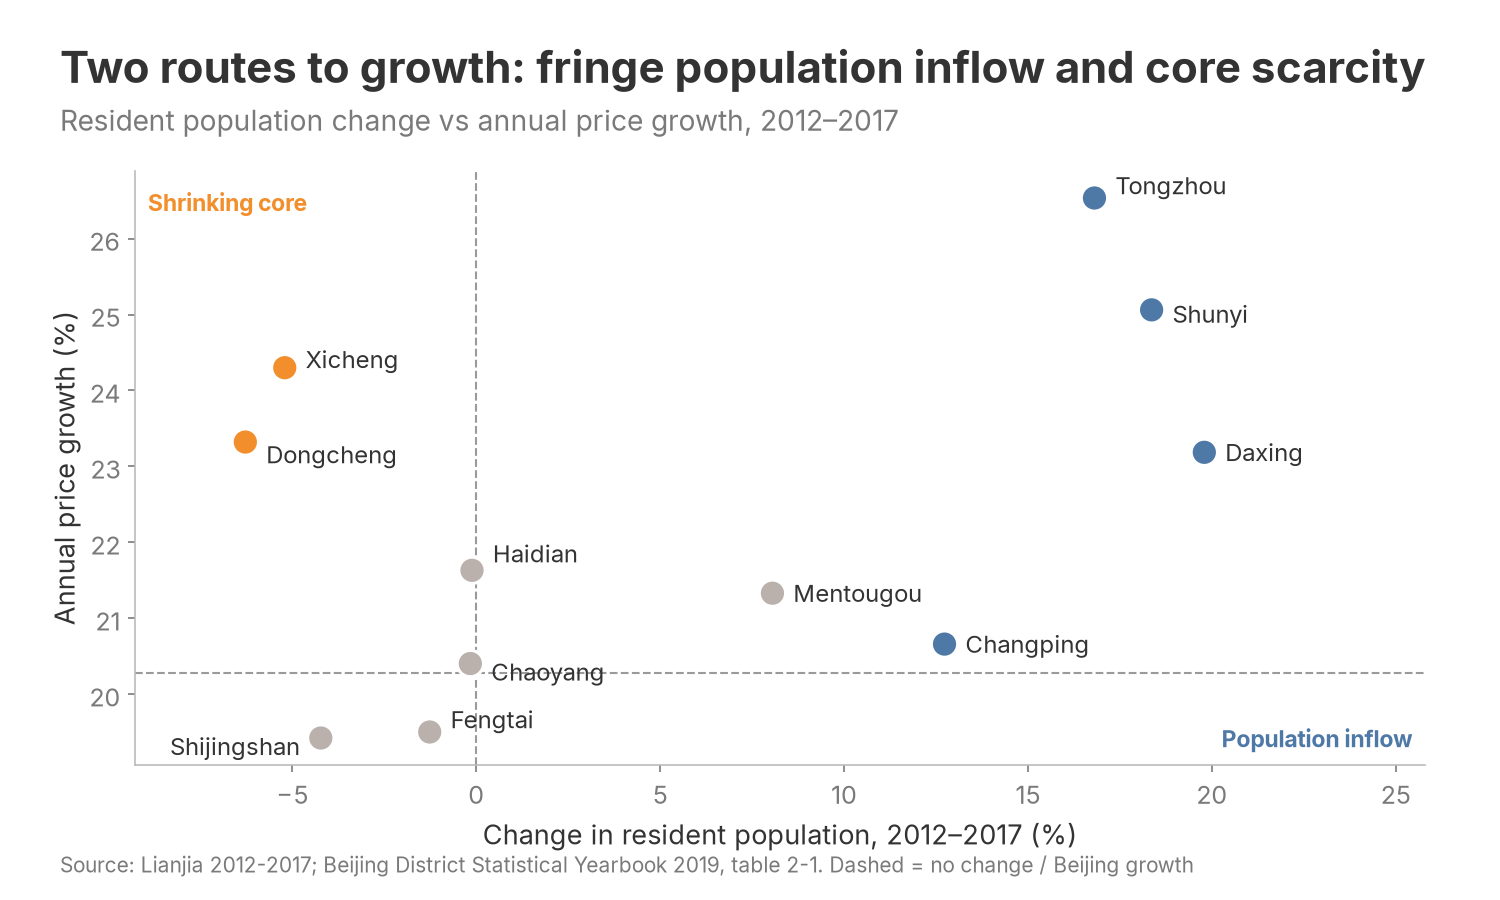

In [ ]:
fund = pd.DataFrame({"cagr": dcagr, "popg": (pop["2017"] / pop["2012"] - 1) * 100}).dropna()
print(fund.round(1), "\ncorrelation", round(fund.corr().iloc[0, 1], 2))
fig, ax = bs.new_chart("Two routes to growth: fringe population inflow and core scarcity",
                       f"Resident population change vs annual price growth, {BASE}–{END}")
inflow = fund.popg > 10
core = fund.index.isin(["Dongcheng", "Xicheng"])
cols = [bs.HIGHLIGHT if i else (bs.HIGHLIGHT_2 if c else bs.CONTEXT) for i, c in zip(inflow, core)]
ax.scatter(fund.popg, fund.cagr, s=160, color=cols, edgecolor="white", lw=1.5, zorder=3)
POFF = {"Tongzhou": (10, 6, "left"), "Shunyi": (10, -2, "left"), "Daxing": (10, 0, "left"),
        "Changping": (10, 0, "left"), "Mentougou": (10, 0, "left"), "Xicheng": (10, 4, "left"),
        "Dongcheng": (10, -6, "left"), "Haidian": (10, 8, "left"), "Chaoyang": (10, -4, "left"),
        "Fengtai": (10, 6, "left"), "Shijingshan": (-10, -4, "right"), "Yizhuang": (10, 0, "left")}
for d_, r in fund.iterrows():
    dx, dy, ha = POFF.get(d_, (10, 0, "left"))
    ax.annotate(d_, (r.popg, r.cagr), xytext=(dx, dy), textcoords="offset points", ha=ha, va="center", fontsize=11.5)
ax.axvline(0, color="#9A9A9A", lw=1, ls="--")
ax.axhline(overall_cagr * 100, color="#9A9A9A", lw=1, ls="--")
ax.text(0.99, 0.03, "Population inflow", transform=ax.transAxes, ha="right", fontsize=11, color=bs.HIGHLIGHT, fontweight="bold")
ax.text(0.01, 0.97, "Shrinking core", transform=ax.transAxes, ha="left", va="top", fontsize=11, color=bs.HIGHLIGHT_2, fontweight="bold")
ax.set_xlim(fund.popg.min() - 3, fund.popg.max() + 6)
ax.set_xlabel(f"Change in resident population, {BASE}–{END} (%)")
ax.set_ylabel("Annual price growth (%)")
bs.finish(fig, f"{OUT}/PD4_population_vs_growth.png",
          "Lianjia 2012-2017; Beijing District Statistical Yearbook 2019, table 2-1. Dashed = no change / Beijing growth")
show(f"{OUT}/PD4_population_vs_growth.png")

## R. Risk: stability and liquidity
**R1. Which districts and property types have the most stable price trends?**
Volatility = standard deviation of quarter-on-quarter change in median price per m², 2012-2017.

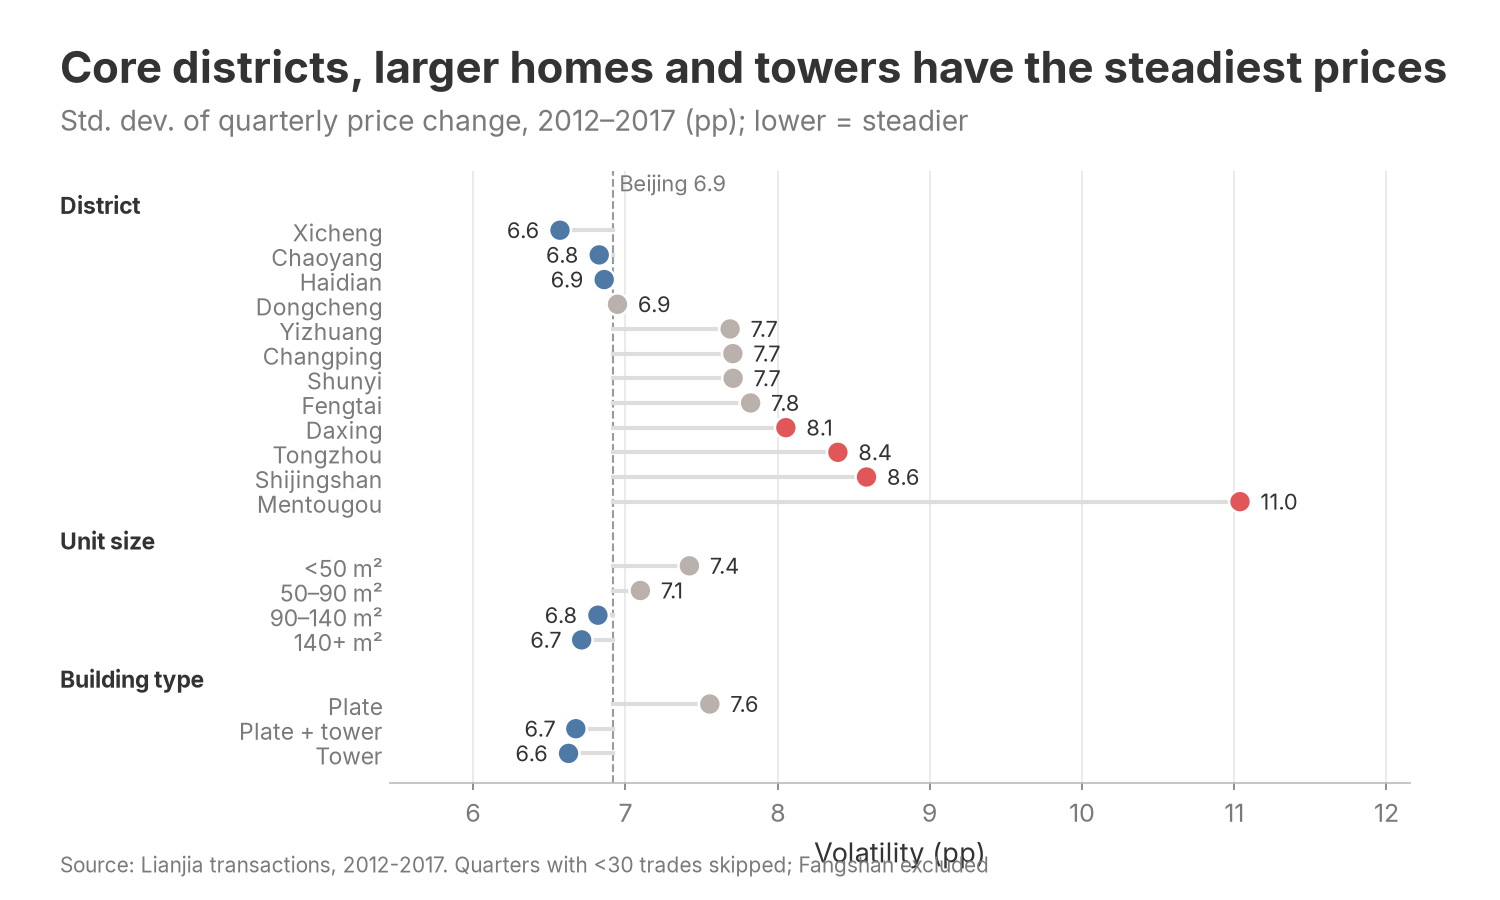

In [ ]:
def volatility(col, data=df, min_n=30):
    q = data.groupby([col, "quarter"], observed=True).price.agg(["median", "size"])
    q = q[q["size"] >= min_n]["median"].unstack()
    return q.pct_change(axis=1).std(axis=1) * 100


vol_d = volatility("dname").drop("Fangshan")
vol_vals = {}
for col in ["size_lab", "btype", "age_lab"]:
    vol_vals.update(volatility(col).to_dict())
vol_vals.update(vol_d.to_dict())
city_vol = df.groupby("quarter").price.median().pct_change().std() * 100
vol_groups = [("District", list(vol_d.sort_values().index)),
              ("Unit size", SIZE_ORDER), ("Building type", ["Plate", "Plate + tower", "Tower"])]   # age bands all ~7.1-7.2: left out
grouped_dots(vol_groups, vol_vals, "Core districts, larger homes and towers have the steadiest prices",
             "Std. dev. of quarterly price change, 2012–2017 (pp); lower = steadier",
             "Volatility (pp)", f"{OUT}/R1_price_volatility.png", ref=city_vol, ref_label=f"Beijing {city_vol:.1f}",
             fmt="{:.1f}", colour_rule=lambda v: bs.NEGATIVE if v > city_vol * 1.15 else (bs.HIGHLIGHT if v < city_vol else bs.CONTEXT),
             src=SRC + ". Quarters with <30 trades skipped; Fangshan excluded")
show(f"{OUT}/R1_price_volatility.png")

**R2. Which districts and property types face the greatest resale liquidity risk? (2017)**
Median DOM = a typical sale; 75th percentile DOM = the slow quarter of sales (tail risk).

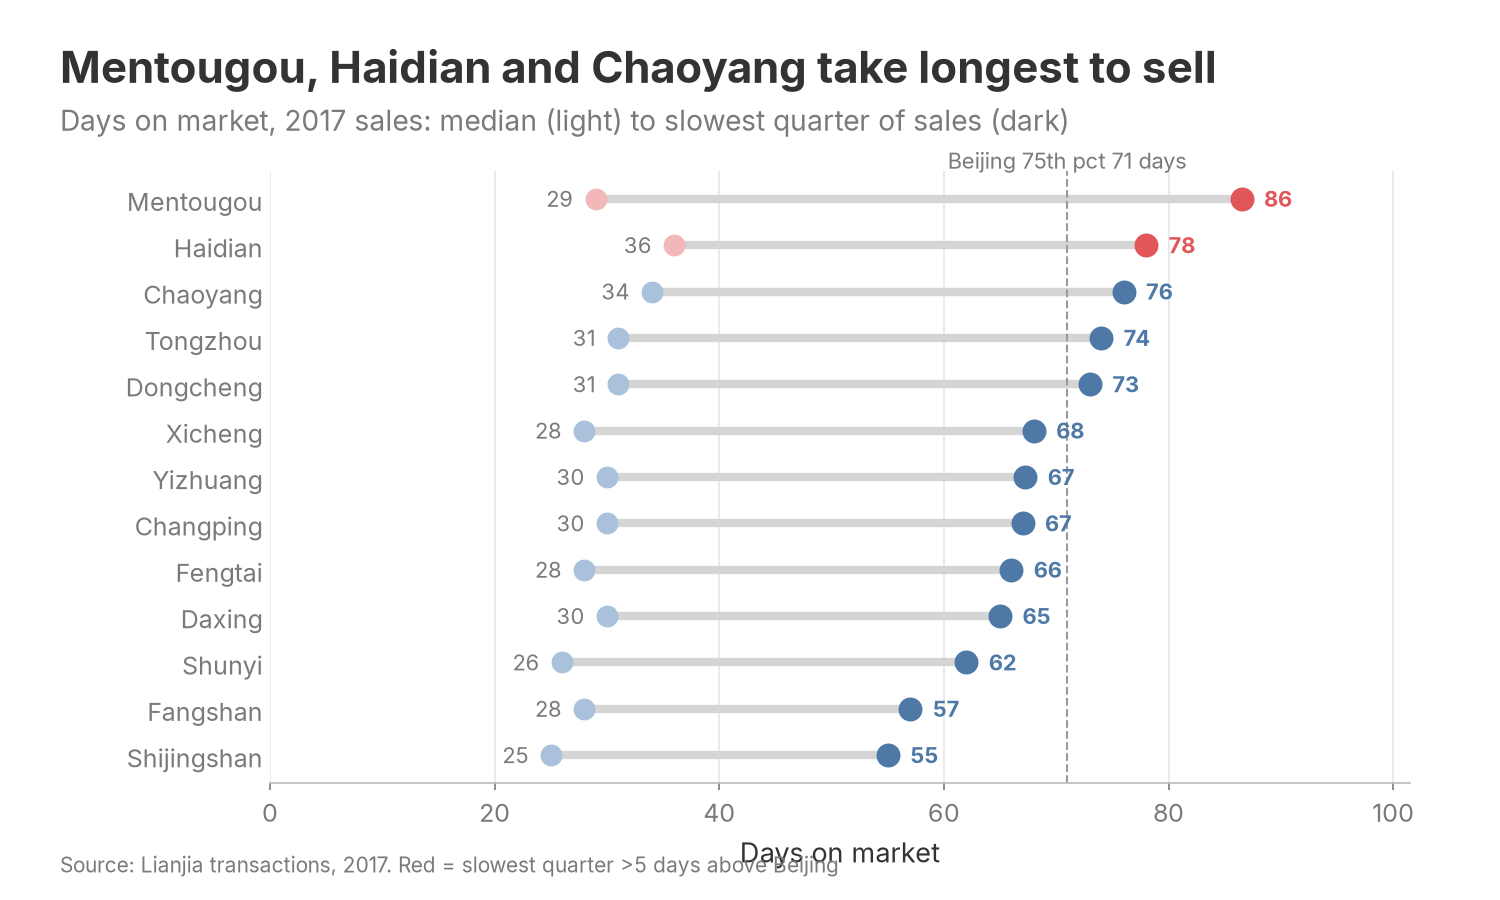

In [ ]:
d17d = df[(df.trade_year == 2017) & df.DOM.notna()]


def dom_stats(col):
    return d17d.groupby(col, observed=True).DOM.agg(med="median", p75=lambda s: s.quantile(0.75), n="size")


dd = dom_stats("dname").sort_values("p75")
city_p75 = d17d.DOM.quantile(0.75)
fig, ax = bs.new_chart("Mentougou, Haidian and Chaoyang take longest to sell",
                       "Days on market, 2017 sales: median (light) to slowest quarter of sales (dark)",
                       rect=(0.18, 0.13, 0.76, 0.68))
for i, (d_, r) in enumerate(dd.iterrows()):
    risky = r.p75 > city_p75 + 5
    c = bs.NEGATIVE if risky else bs.HIGHLIGHT
    ax.plot([r.med, r.p75], [i, i], color="#D5D5D5", lw=4, solid_capstyle="round", zorder=1)
    ax.scatter(r.med, i, s=90, color="#A9C1DB" if not risky else "#F2B8B9", zorder=3)
    ax.scatter(r.p75, i, s=110, color=c, zorder=3)
    ax.text(r.p75 + 2, i, f"{r.p75:.0f}", va="center", fontsize=10.5, color=c, fontweight="bold")
    ax.text(r.med - 2, i, f"{r.med:.0f}", va="center", ha="right", fontsize=10.5, color=bs.MUTED)
ax.axvline(city_p75, color="#9A9A9A", lw=1, ls="--")
ax.text(city_p75, len(dd) - 0.35, f"Beijing 75th pct {city_p75:.0f} days", ha="center", fontsize=10.5, color=bs.MUTED)
ax.set_yticks(range(len(dd)), dd.index)
ax.set_xlim(0, dd.p75.max() + 15)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Days on market")
bs.xgrid(ax)
bs.finish(fig, f"{OUT}/R2_dom_by_district.png", "Lianjia transactions, 2017. Red = slowest quarter >5 days above Beijing")
show(f"{OUT}/R2_dom_by_district.png")

**R3. Which property types sell fastest / face the most liquidity risk? (2017)**

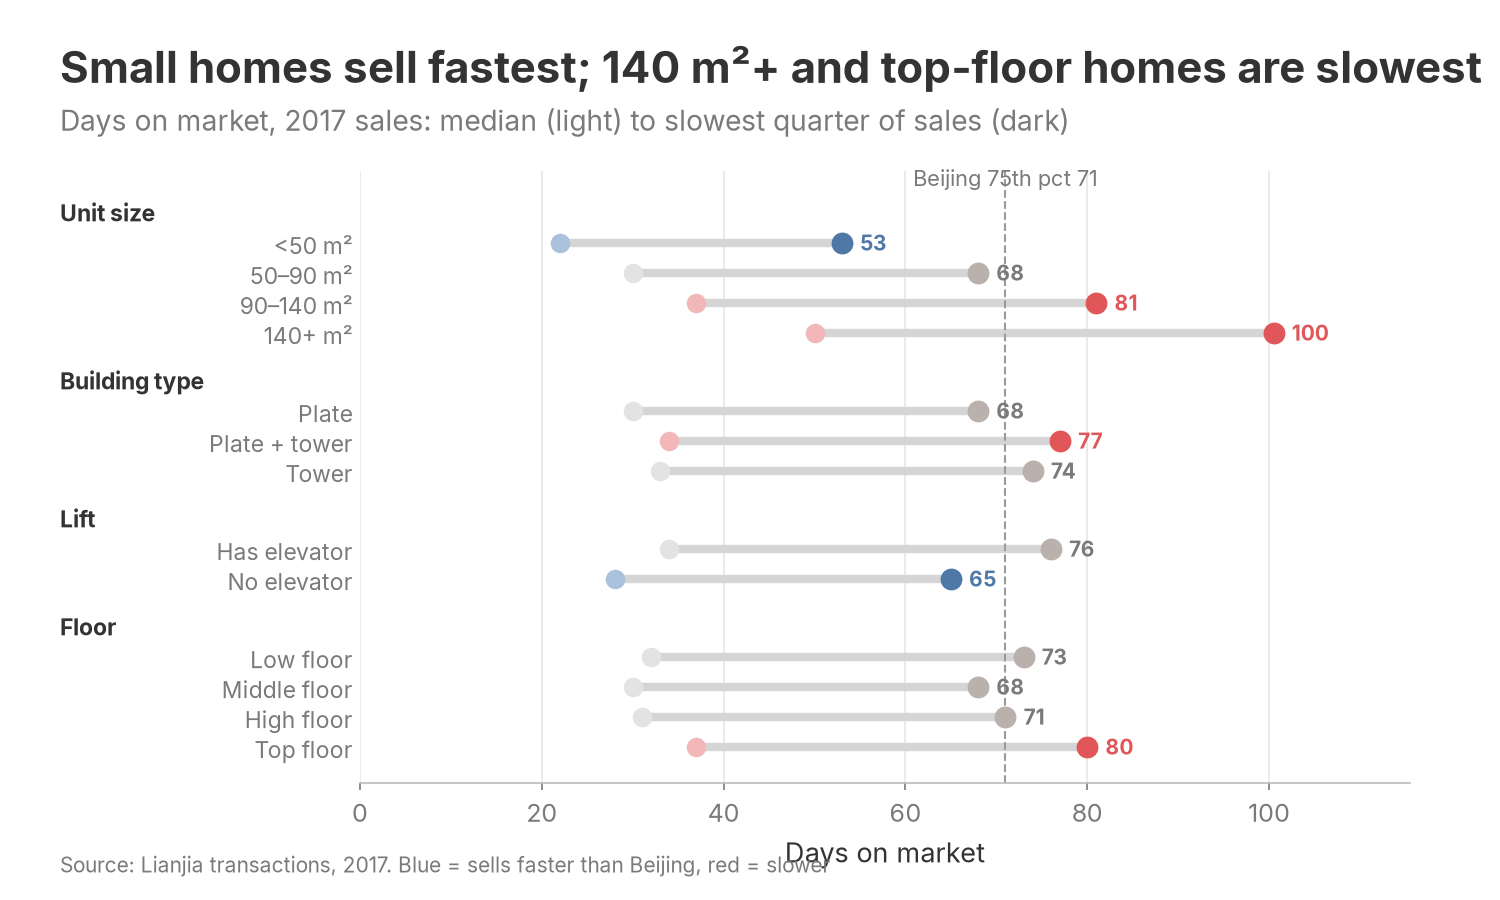

In [ ]:
seg_groups = [("Unit size", SIZE_ORDER), ("Building type", ["Plate", "Plate + tower", "Tower"]),
              ("Lift", ["Has elevator", "No elevator"]),
              ("Floor", ["Low floor", "Middle floor", "High floor", "Top floor"])]   # age and subway: see checks table
seg = pd.concat([dom_stats(c) for c in ["size_lab", "age_lab", "btype", "subway_lab", "elev_lab", "floor_lab"]])
rows, heads, yc = [], [], 0
for head, labs in seg_groups:
    heads.append((yc, head)); yc += 1
    for lab in labs:
        rows.append((yc, lab, seg.loc[lab, "med"], seg.loc[lab, "p75"])); yc += 1
    yc += 0.6
fig, ax = bs.new_chart("Small homes sell fastest; 140 m²+ and top-floor homes are slowest",
                       "Days on market, 2017 sales: median (light) to slowest quarter of sales (dark)",
                       rect=(0.24, 0.13, 0.70, 0.68))
for yy, lab, med, p75 in rows:
    risky, fast = p75 > city_p75 + 5, p75 < city_p75 - 5
    c = bs.NEGATIVE if risky else (bs.HIGHLIGHT if fast else bs.CONTEXT)
    ax.plot([med, p75], [yy, yy], color="#D5D5D5", lw=4, solid_capstyle="round", zorder=1)
    ax.scatter(med, yy, s=70, color="#E3E3E3" if c == bs.CONTEXT else ("#F2B8B9" if risky else "#A9C1DB"), zorder=3)
    ax.scatter(p75, yy, s=90, color=c, zorder=3)
    ax.text(p75 + 2, yy, f"{p75:.0f}", va="center", fontsize=10, color=c if c != bs.CONTEXT else bs.MUTED, fontweight="bold")
ax.set_yticks([r[0] for r in rows], [r[1] for r in rows])
tr = blended_transform_factory(fig.transFigure, ax.transData)
for yh, head in heads:
    ax.text(0.04, yh, head, transform=tr, ha="left", va="center", fontsize=11, fontweight="bold")
ax.axvline(city_p75, color="#9A9A9A", lw=1, ls="--")
ax.text(city_p75, -0.9, f"Beijing 75th pct {city_p75:.0f}", ha="center", fontsize=10.5, color=bs.MUTED)
ax.set_ylim(yc - 0.4, -1.4)
ax.set_xlim(0, max(r[3] for r in rows) + 15)
ax.tick_params(axis="y", length=0, labelsize=11)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Days on market")
bs.xgrid(ax)
bs.finish(fig, f"{OUT}/R3_dom_by_segment.png", "Lianjia transactions, 2017. Blue = sells faster than Beijing, red = slower")
show(f"{OUT}/R3_dom_by_segment.png")

**R4. Which districts offer the strongest appreciation relative to these risks?**

             cagr   p75   vol
dname                        
Yizhuang     19.1  67.2   7.7
Shijingshan  19.4  55.0   8.6
Fengtai      19.5  66.0   7.8
Chaoyang     20.4  76.0   6.8
Changping    20.7  67.0   7.7
Mentougou    21.3  86.5  11.0
Haidian      21.6  78.0   6.9
Daxing       23.2  65.0   8.1
Dongcheng    23.3  73.0   6.9
Xicheng      24.3  68.0   6.6
Shunyi       25.1  62.0   7.7
Tongzhou     26.5  74.0   8.4


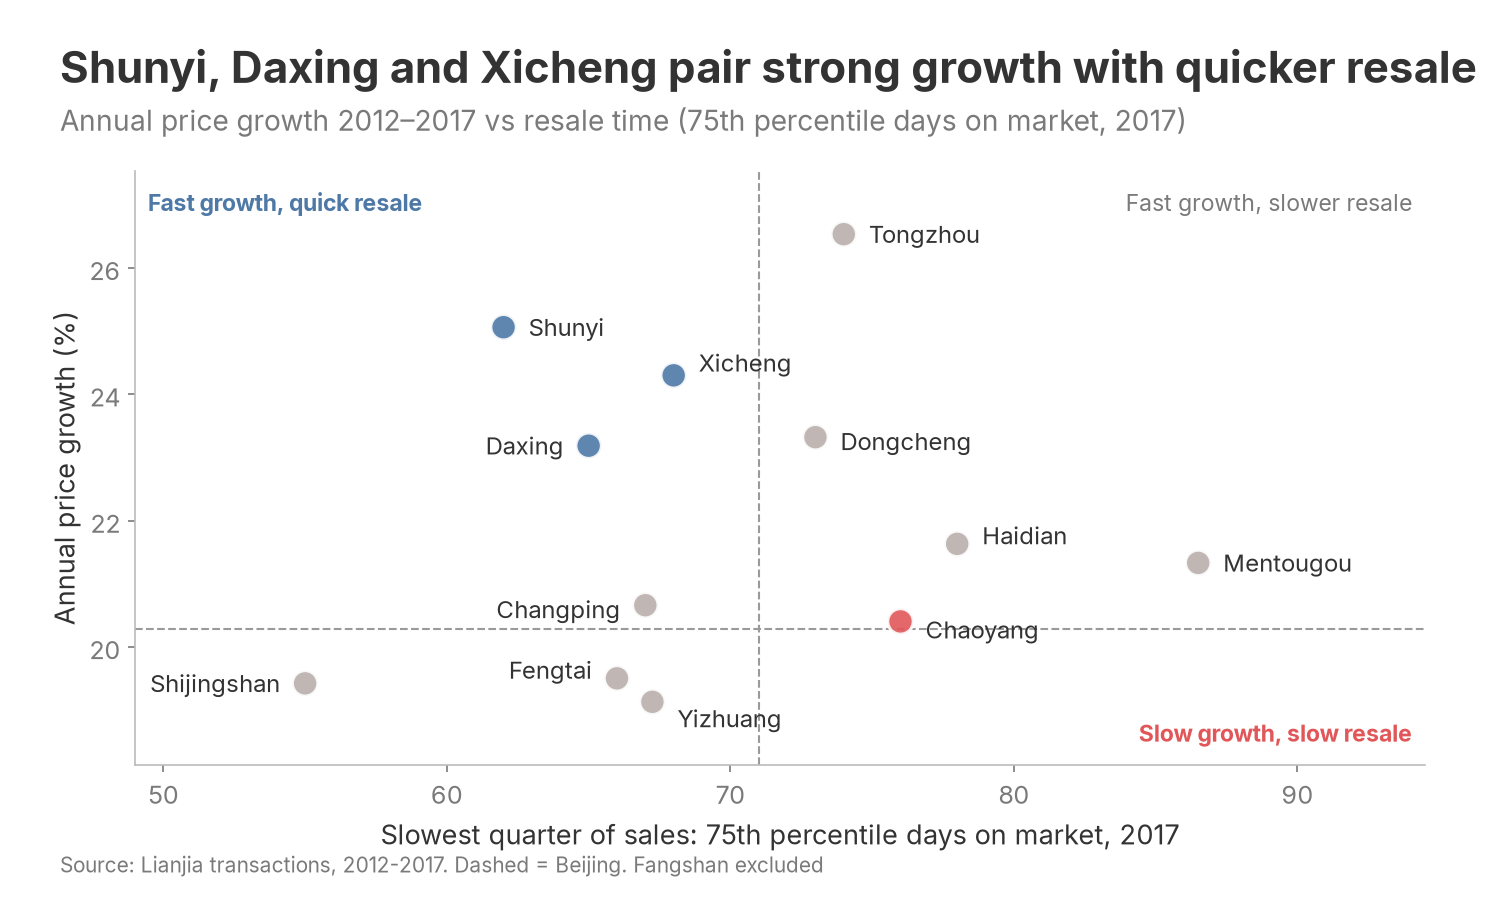

In [ ]:
rr = pd.DataFrame({"cagr": dcagr, "p75": dd.p75, "vol": vol_d}).dropna()
print(rr.round(1).sort_values("cagr"))
fig, ax = bs.new_chart("Shunyi, Daxing and Xicheng pair strong growth with quicker resale",
                       f"Annual price growth {BASE}–{END} vs resale time (75th percentile days on market, 2017)")
xm, ym = city_p75, overall_cagr * 100
good = (rr.cagr > ym + 1) & (rr.p75 <= xm)
bad = (rr.cagr <= ym + 1) & (rr.p75 > xm)
cols = [bs.HIGHLIGHT if g_ else (bs.NEGATIVE if b_ else bs.CONTEXT) for g_, b_ in zip(good, bad)]
ax.scatter(rr.p75, rr.cagr, s=150, color=cols, alpha=0.9, edgecolor="white", lw=1.5, zorder=3)
ROFF = {d_: (12, 0, "left") for d_ in rr.index}
ROFF.update({"Xicheng": (12, 6, "left"), "Dongcheng": (12, -2, "left"), "Daxing": (-12, 0, "right"),
             "Fengtai": (-12, 4, "right"), "Changping": (-12, -2, "right"), "Yizhuang": (12, -8, "left"),
             "Shijingshan": (-12, 0, "right"), "Haidian": (12, 4, "left"), "Chaoyang": (12, -4, "left")})
for d_, r in rr.iterrows():
    dx, dy, ha = ROFF[d_]
    ax.annotate(d_, (r.p75, r.cagr), xytext=(dx, dy), textcoords="offset points", ha=ha, va="center", fontsize=11.5)
ax.axvline(xm, color="#9A9A9A", lw=1, ls="--")
ax.axhline(ym, color="#9A9A9A", lw=1, ls="--")
q = dict(transform=ax.transAxes, fontsize=11)
ax.text(0.01, 0.97, "Fast growth, quick resale", ha="left", va="top", color=bs.HIGHLIGHT, fontweight="bold", **q)
ax.text(0.99, 0.97, "Fast growth, slower resale", ha="right", va="top", color=bs.MUTED, **q)
ax.text(0.99, 0.03, "Slow growth, slow resale", ha="right", va="bottom", color=bs.NEGATIVE, fontweight="bold", **q)
ax.set_xlim(rr.p75.min() - 6, rr.p75.max() + 8)
ax.set_ylim(rr.cagr.min() - 1, rr.cagr.max() + 1)
ax.set_xlabel("Slowest quarter of sales: 75th percentile days on market, 2017")
ax.set_ylabel("Annual price growth (%)")
bs.finish(fig, f"{OUT}/R4_growth_vs_liquidity_risk.png", SRC + ". Dashed = Beijing. Fangshan excluded")
show(f"{OUT}/R4_growth_vs_liquidity_risk.png")

**R5. Affordability stretch: fast-growth districts now cost the most months of local income (yearbook 2-14)**

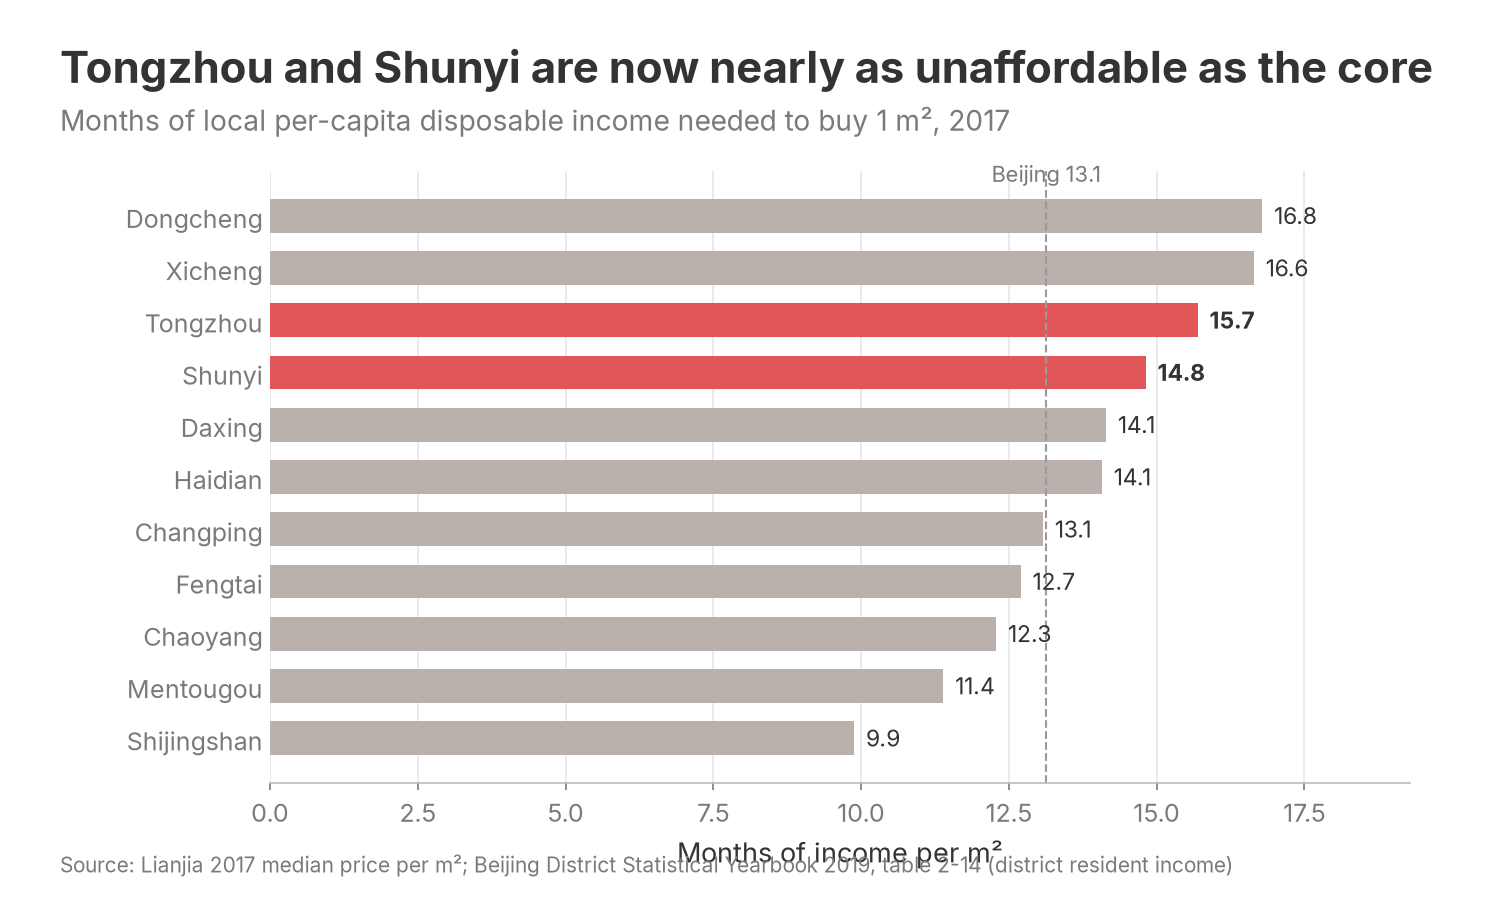

In [ ]:
aff = (dist_year[END] / (income["2017"] / 12)).dropna().drop("Fangshan", errors="ignore").sort_values()
city_aff = yearly[END] / (income.loc["Beijing", "2017"] / 12)
fig, ax = bs.new_chart("Tongzhou and Shunyi are now nearly as unaffordable as the core",
                       "Months of local per-capita disposable income needed to buy 1 m², 2017", rect=(0.18, 0.13, 0.76, 0.68))
cols = [bs.NEGATIVE if d_ in ("Tongzhou", "Shunyi") else bs.CONTEXT for d_ in aff.index]
ax.barh(aff.index, aff.values, color=cols, height=0.65)
for i, v in enumerate(aff.values):
    ax.text(v + 0.2, i, f"{v:.1f}", va="center", fontsize=11, fontweight="bold" if cols[i] == bs.NEGATIVE else "normal")
ax.axvline(city_aff, color="#9A9A9A", lw=1, ls="--")
ax.text(city_aff, len(aff) - 0.35, f"Beijing {city_aff:.1f}", ha="center", fontsize=10.5, color=bs.MUTED)
ax.set_xlim(0, aff.max() + 2.5)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Months of income per m²")
bs.xgrid(ax)
bs.finish(fig, f"{OUT}/R5_affordability.png",
          "Lianjia 2017 median price per m²; Beijing District Statistical Yearbook 2019, table 2-14 (district resident income)")
show(f"{OUT}/R5_affordability.png")

## Numbers behind the charts (for validation)

In [ ]:
checks = {
    "district_growth": pd.DataFrame({"cagr_pct": dcagr}).join(dist_n),
    "district_dom_2017": dd,
    "segment_dom_2017": seg,
    "district_volatility": vol_d.rename("volatility_pp").to_frame(),
    "followers_size_age_2017": fol,
    "monthly": monthly,
    "rank_like_for_like": both,
    "population_vs_growth": fund,
    "growth_drivers": R,
}
with pd.ExcelWriter(f"{OUT}/checks_all_charts.xlsx") as xw:
    for k, v in checks.items():
        v.to_excel(xw, sheet_name=k[:31])
print("saved", f"{OUT}/checks_all_charts.xlsx")

saved charts/checks_all_charts.xlsx
